# Volatility — A Complete Guide

---

## What is Volatility?

**Volatility** is the statistical measure of the *dispersion* of returns for a financial asset. In plain terms: how wildly does this asset's price move?

It is the single most important concept in quantitative risk management and options pricing. Every major model — Black-Scholes, VaR, GARCH, Kelly Criterion — has volatility as a central input.

### Two Faces of Volatility

| Type | Computed From | Use Case |
|------|--------------|----------|
| **Historical (Realized)** | Past price data | Risk measurement, backtesting |
| **Implied** | Options market prices | Forward-looking market expectations |

> This notebook focuses entirely on **historical / realized volatility** — measuring it from price data — and the rich family of estimators developed to do so accurately.

---

### Why Does Volatility Matter?

1. **Risk Management**: a portfolio's risk is dominated by vol, not returns
2. **Position Sizing**: Kelly / volatility targeting requires accurate vol estimates
3. **Options Pricing**: the Black-Scholes price is essentially a function of volatility alone
4. **Regime Detection**: high/low vol regimes predict very different market dynamics
5. **Alpha Generation**: volatility itself is a tradeable asset (VIX futures, variance swaps)

---

### What This Notebook Covers

| Part | Topic |
|------|-------|
| **I** | Returns: Simple vs Log |
| **II** | Historical (Close-to-Close) Volatility |
| **III** | Range-Based Estimators (Parkinson, Garman-Klass, Yang-Zhang) |
| **IV** | Realized Volatility from High-Frequency Data |
| **V** | EWMA / RiskMetrics Volatility |
| **VI** | GARCH(1,1) — Theory & Implementation |
| **VII** | Volatility Forecasting Comparison |
| **VIII** | Stylized Facts of Volatility |
| **IX** | Volatility of Volatility (VoV) |
| **X** | Volatility Regime Detection |
| **XI** | Volatility as an ML Feature |

---

# Part I — Returns: Simple vs Log

## 1.1 Why Returns, Not Prices?

Prices are non-stationary (they trend, they compound). Working with raw prices leads to models that break when the price level changes.

**Returns** remove the price level, making the series stationary (approximately) and comparable across assets and time periods.

## 1.2 Simple Returns

$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}} = \frac{P_t}{P_{t-1}} - 1$$

**Properties:**
- Intuitive: a 10% return means the investment grew by 10%
- Multi-period: $(1+R_1)(1+R_2)\cdots(1+R_T) - 1$
- Bounded below at $-1$ (you can't lose more than 100%)
- Cross-sectionally additive: a portfolio return = weighted sum of asset returns

## 1.3 Log Returns

$$r_t = \ln\!\left(\frac{P_t}{P_{t-1}}\right) = \ln P_t - \ln P_{t-1}$$

**Properties:**
- **Temporally additive**: $r_{t,T} = r_t + r_{t+1} + \cdots + r_T$ — makes multi-period analysis trivial
- **Symmetric**: a +50% move followed by a -50% move returns to the origin (unlike simple returns)
- **Approximately normal**: by CLT, the sum of log returns is normally distributed
- **Volatility scaling**: $\sigma_T = \sigma_1 \sqrt{T}$ holds exactly for log returns of an IID process

## 1.4 Relationship Between Them

For small moves ($|R_t| \ll 1$): $\quad r_t \approx R_t - \frac{1}{2}R_t^2$

The $-\frac{1}{2}R_t^2$ term is the **Itô correction** — it becomes significant in high-volatility regimes and when annualizing.

> **Convention in this notebook**: we use **log returns** throughout, as they are the standard in quantitative finance for volatility work.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.figsize': (14, 5),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'lines.linewidth': 2,
})
np.random.seed(42)
print('Setup complete')

Setup complete


## 1.5 Synthetic Data Generation

We simulate a realistic price path using **Geometric Brownian Motion (GBM)** — the model underlying Black-Scholes. It generates log-normally distributed prices with a constant drift and volatility, giving us a clean ground truth to build intuition.

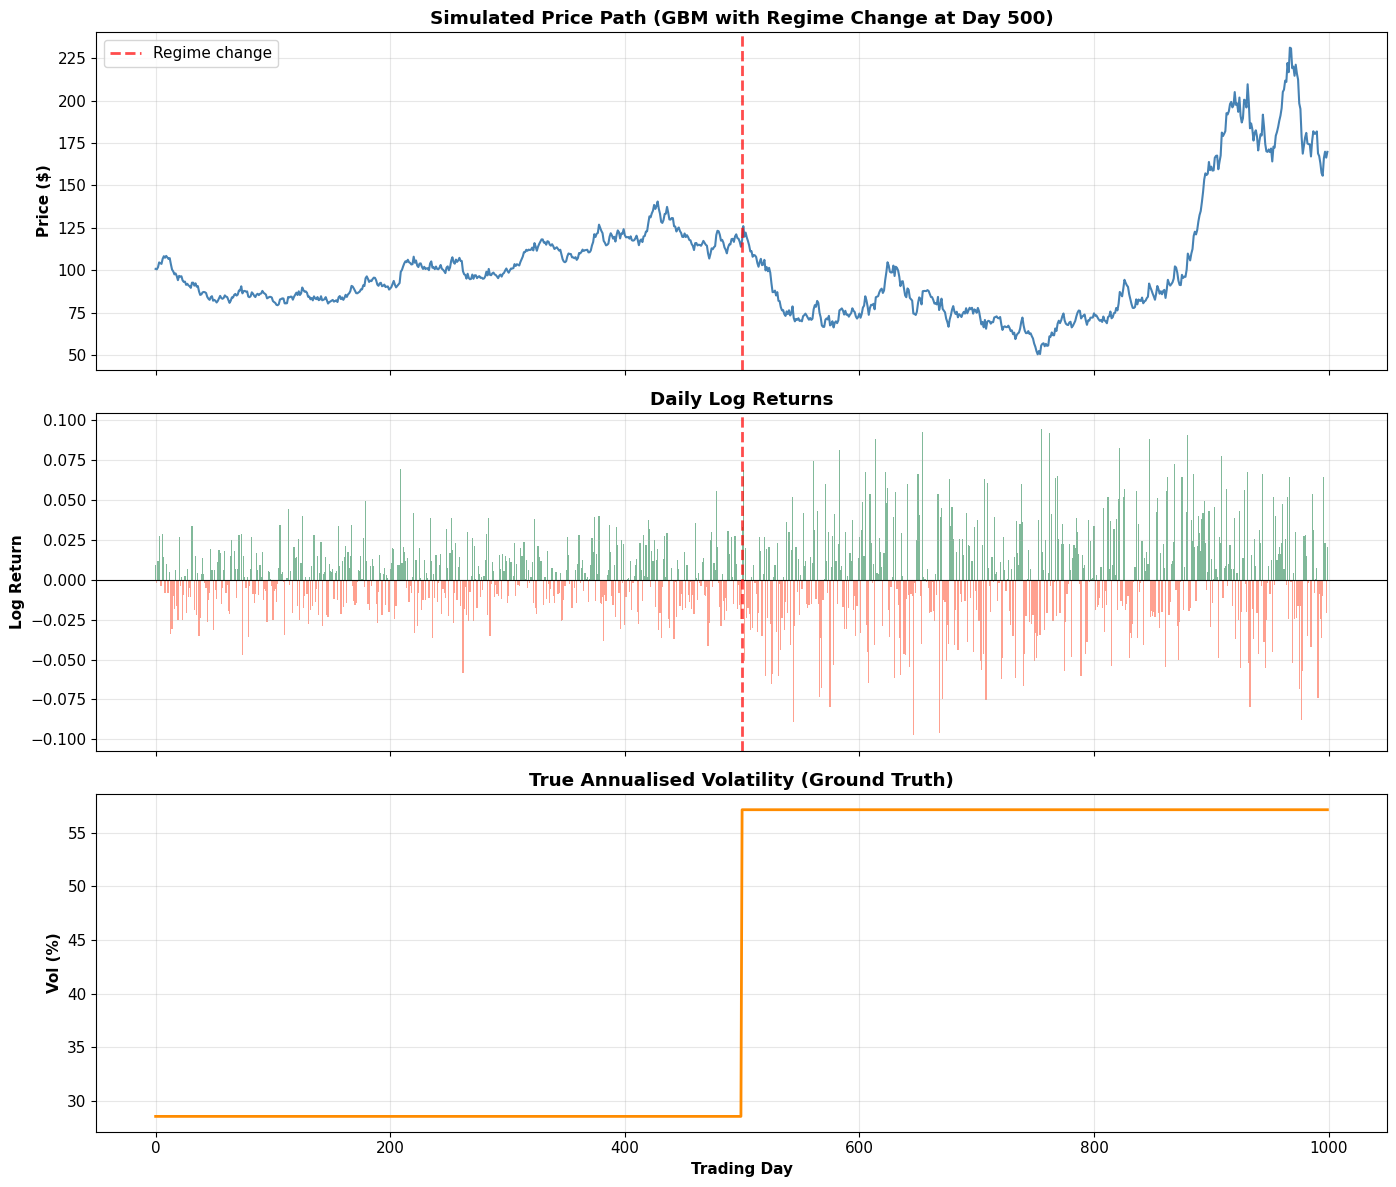

Simulation summary:
  Days           : 1000
  True vol Reg 1 : 28.6%  annualised
  True vol Reg 2 : 57.1%  annualised
  Realised mean  : 0.000529 per day


In [2]:
# ── Geometric Brownian Motion ─────────────────────────────────────────────────
# dS = μ S dt + σ S dW  =>  S_t = S_0 * exp((μ - σ²/2)t + σ W_t)

np.random.seed(42)

n_days   = 1000          # trading days (~4 years)
S0       = 100.0         # starting price
mu_daily = 0.0003        # ~7.5% annual drift
TRUE_VOL = 0.018         # ~28.6% annual true daily vol (annualised: σ√252)
dt       = 1.0           # daily steps

# Simulate two volatility regimes (we'll use this later)
# Low-vol first half, high-vol second half
vol_path = np.concatenate([
    np.full(n_days // 2, TRUE_VOL),
    np.full(n_days // 2, TRUE_VOL * 2.0)
])

Z = np.random.standard_normal(n_days)
log_returns = (mu_daily - 0.5 * vol_path**2) + vol_path * Z
prices      = S0 * np.exp(np.cumsum(log_returns))
prices      = np.concatenate([[S0], prices])           # prepend S0

# Also build synthetic OHLC (needed for range-based estimators later)
# H = C * exp(|ε| * intraday_factor), L = C * exp(-|ε| * intraday_factor)
intraday_factor = 0.6
H = prices[1:] * np.exp(np.abs(np.random.normal(0, vol_path * intraday_factor, n_days)))
L = prices[1:] * np.exp(-np.abs(np.random.normal(0, vol_path * intraday_factor, n_days)))
O = prices[:-1]
C = prices[1:]
H = np.maximum(H, np.maximum(O, C))
L = np.minimum(L, np.minimum(O, C))

# Returns
simple_rets = (C - O) / O
log_rets    = np.log(C / O)

t = np.arange(n_days)

# ── Figure: price path ────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

axes[0].plot(t, prices[1:], color='steelblue', linewidth=1.5)
axes[0].axvline(n_days // 2, color='red', linestyle='--', alpha=0.7, label='Regime change')
axes[0].set_title('Simulated Price Path (GBM with Regime Change at Day 500)')
axes[0].set_ylabel('Price ($)')
axes[0].legend()

axes[1].bar(t, log_rets, color=np.where(log_rets >= 0, 'seagreen', 'tomato'), alpha=0.6, width=1)
axes[1].axhline(0, color='k', linewidth=0.8)
axes[1].axvline(n_days // 2, color='red', linestyle='--', alpha=0.7)
axes[1].set_title('Daily Log Returns')
axes[1].set_ylabel('Log Return')

axes[2].plot(t, vol_path * np.sqrt(252) * 100, color='darkorange', linewidth=2)
axes[2].set_title('True Annualised Volatility (Ground Truth)')
axes[2].set_ylabel('Vol (%)')
axes[2].set_xlabel('Trading Day')

plt.tight_layout()
plt.show()

print(f'Simulation summary:')
print(f'  Days           : {n_days}')
print(f'  True vol Reg 1 : {TRUE_VOL * np.sqrt(252):.1%}  annualised')
print(f'  True vol Reg 2 : {TRUE_VOL * 2 * np.sqrt(252):.1%}  annualised')
print(f'  Realised mean  : {log_rets.mean():.6f} per day')

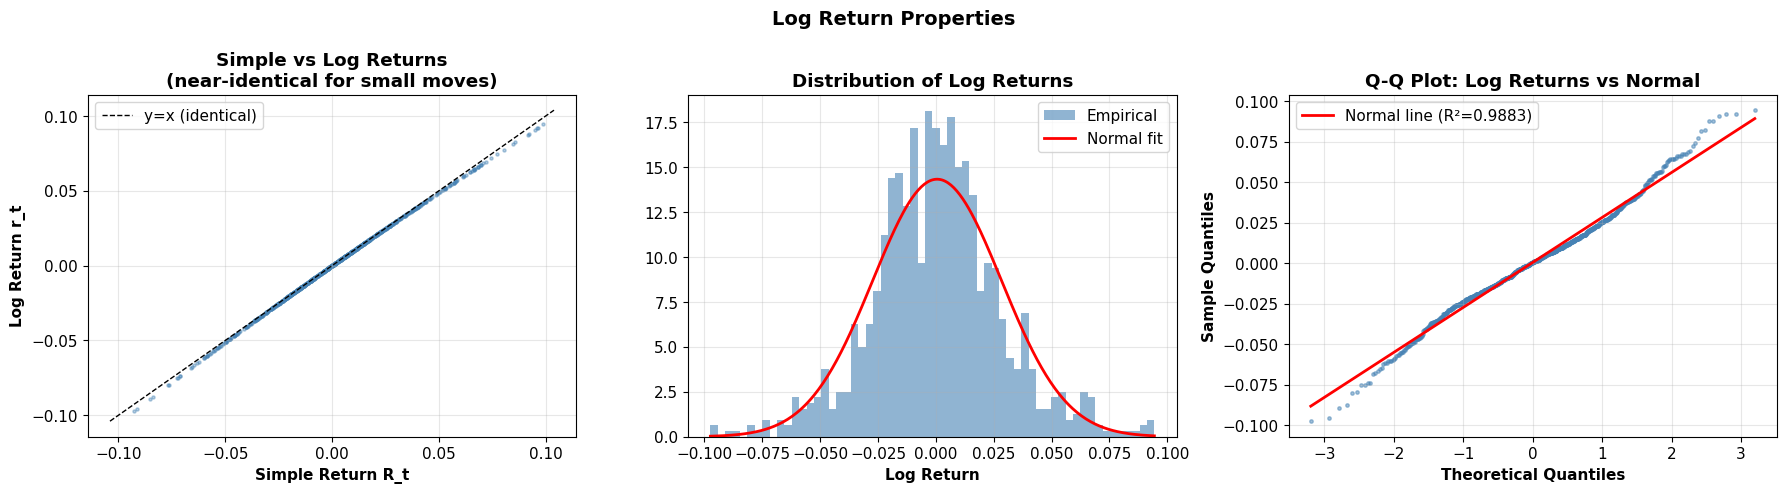

Daily log return statistics:
  Mean            : 0.000529  (13.34% annualised)
  Std (daily)     : 0.027826  (44.17% annualised)
  Skewness        : 0.0944  (0 = symmetric)
  Excess Kurtosis : 0.9409  (0 = normal, >0 = fat tails)
  Jarque-Bera p   : 0.0000  (<0.05 = reject normality)


In [3]:
# ── Simple vs Log returns: distributional comparison ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter: simple vs log
ax = axes[0]
ax.scatter(simple_rets, log_rets, s=5, alpha=0.4, color='steelblue')
lim = max(abs(simple_rets).max(), abs(log_rets).max()) * 1.05
ax.plot([-lim, lim], [-lim, lim], 'k--', linewidth=1, label='y=x (identical)')
ax.set_xlabel('Simple Return R_t')
ax.set_ylabel('Log Return r_t')
ax.set_title('Simple vs Log Returns\n(near-identical for small moves)')
ax.legend()

# Distribution of log returns
ax = axes[1]
mu_r, std_r = log_rets.mean(), log_rets.std()
x_range = np.linspace(log_rets.min(), log_rets.max(), 300)
ax.hist(log_rets, bins=60, density=True, color='steelblue', alpha=0.6, label='Empirical')
ax.plot(x_range, stats.norm.pdf(x_range, mu_r, std_r),
        color='red', linewidth=2, label='Normal fit')
ax.set_xlabel('Log Return')
ax.set_title('Distribution of Log Returns')
ax.legend()

# Q-Q plot
ax = axes[2]
(osm, osr), (slope, intercept, r) = stats.probplot(log_rets, dist='norm')
ax.scatter(osm, osr, s=6, alpha=0.5, color='steelblue')
ax.plot(osm, slope * np.array(osm) + intercept, 'r-', linewidth=2, label=f'Normal line (R²={r**2:.4f})')
ax.set_xlabel('Theoretical Quantiles')
ax.set_ylabel('Sample Quantiles')
ax.set_title('Q-Q Plot: Log Returns vs Normal')
ax.legend()

plt.suptitle('Log Return Properties', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Stats summary
kurt = stats.kurtosis(log_rets)
skew = stats.skew(log_rets)
_, jb_pval = stats.jarque_bera(log_rets)
print(f'Daily log return statistics:')
print(f'  Mean            : {mu_r:.6f}  ({mu_r*252:.2%} annualised)')
print(f'  Std (daily)     : {std_r:.6f}  ({std_r*np.sqrt(252):.2%} annualised)')
print(f'  Skewness        : {skew:.4f}  (0 = symmetric)')
print(f'  Excess Kurtosis : {kurt:.4f}  (0 = normal, >0 = fat tails)')
print(f'  Jarque-Bera p   : {jb_pval:.4f}  (<0.05 = reject normality)')

In [4]:
# ── Plotly 3D: Return distribution surface — Low Vol vs High Vol regime ───────
reg1 = log_rets[:n_days // 2]
reg2 = log_rets[n_days // 2:]

x_grid = np.linspace(-0.12, 0.12, 300)
pdf1   = stats.norm.pdf(x_grid, reg1.mean(), reg1.std())
pdf2   = stats.norm.pdf(x_grid, reg2.mean(), reg2.std())

fig = go.Figure()

# ── Ribbon surfaces (filled area under each PDF curve) ────────────────────────
# Shape: (2, N) — row 0 = floor z=0, row 1 = pdf curve
for y_val, pdf, color, name in [
    (0.0, pdf1, 'steelblue',  f'Regime 1 — Low Vol (σ={reg1.std()*np.sqrt(252):.1%} ann.)'),
    (1.0, pdf2, 'darkorange', f'Regime 2 — High Vol (σ={reg2.std()*np.sqrt(252):.1%} ann.)'),
]:
    X2 = np.vstack([x_grid, x_grid])                  # (2, 300)
    Y2 = np.full_like(X2, y_val)                       # (2, 300) all same y
    Z2 = np.vstack([np.zeros_like(pdf), pdf])          # (2, 300) floor → curve

    # Filled ribbon
    fig.add_trace(go.Surface(
        x=X2, y=Y2, z=Z2,
        colorscale=[[0, color], [1, color]],
        opacity=0.35, showscale=False, name=name,
        hoverinfo='skip'
    ))
    # Curve line on top
    fig.add_trace(go.Scatter3d(
        x=x_grid, y=np.full_like(x_grid, y_val), z=pdf,
        mode='lines',
        line=dict(color=color, width=5),
        name=name,
    ))

fig.update_layout(
    title=dict(text='3D: Return Distribution — Low Vol vs High Vol Regime',
               font=dict(size=15, color='black')),
    scene=dict(
        xaxis_title='Log Return',
        yaxis=dict(title='Regime', tickvals=[0, 1],
                   ticktext=['Regime 1<br>(σ=18%)', 'Regime 2<br>(σ=36%)']),
        zaxis_title='Probability Density',
        camera=dict(eye=dict(x=1.6, y=-1.6, z=0.8)),
        bgcolor='white',
    ),
    height=600, width=900,
    showlegend=True,
    margin=dict(l=0, r=0, t=60, b=0),
)
fig.show()

print(f'Regime 1: σ_daily = {reg1.std():.5f}  ({reg1.std()*np.sqrt(252):.1%} ann.)')
print(f'Regime 2: σ_daily = {reg2.std():.5f}  ({reg2.std()*np.sqrt(252):.1%} ann.)')
print(f'Vol ratio: {reg2.std() / reg1.std():.2f}x')

Regime 1: σ_daily = 0.01764  (28.0% ann.)
Regime 2: σ_daily = 0.03517  (55.8% ann.)
Vol ratio: 1.99x


## 1.6 Annualisation Convention

Daily volatility is almost always reported in **annualised** form for comparability:

$$\sigma_{\text{annual}} = \sigma_{\text{daily}} \times \sqrt{252}$$

The $\sqrt{252}$ comes from the **square-root-of-time rule**: if daily returns are IID, the variance scales linearly with time, so standard deviation scales with $\sqrt{T}$.

| Frequency | Scale Factor | Typical Use |
|-----------|-------------|-------------|
| Daily | $\times \sqrt{252}$ | Equities |
| Weekly | $\times \sqrt{52}$ | — |
| Monthly | $\times \sqrt{12}$ | Macro |
| Hourly (crypto) | $\times \sqrt{8760}$ | Crypto (24/7) |

> **Important caveat**: The $\sqrt{T}$ rule assumes IID returns. Real markets exhibit **volatility clustering** (large moves follow large moves), making this rule approximate. GARCH models handle this properly (Part VI).

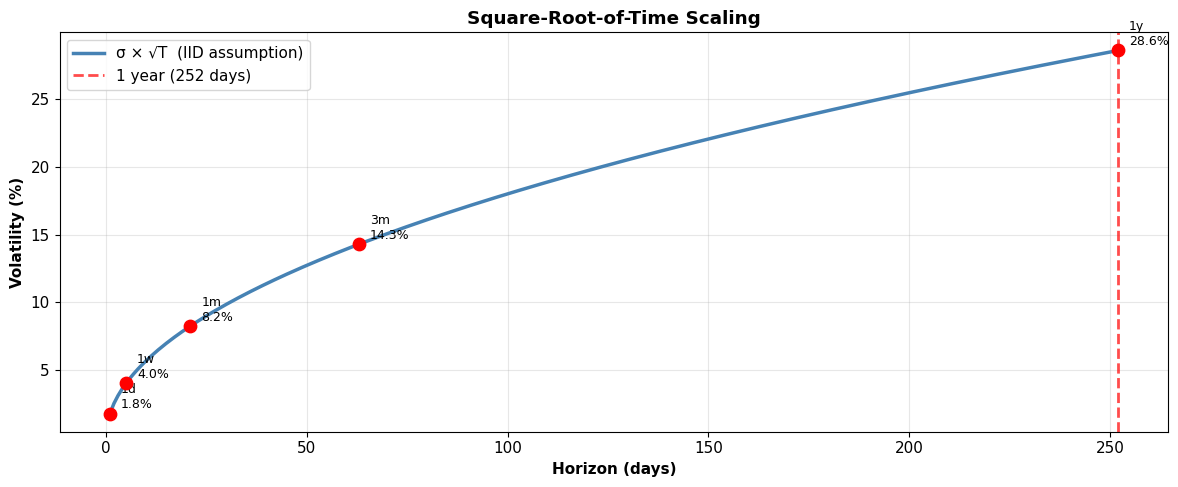

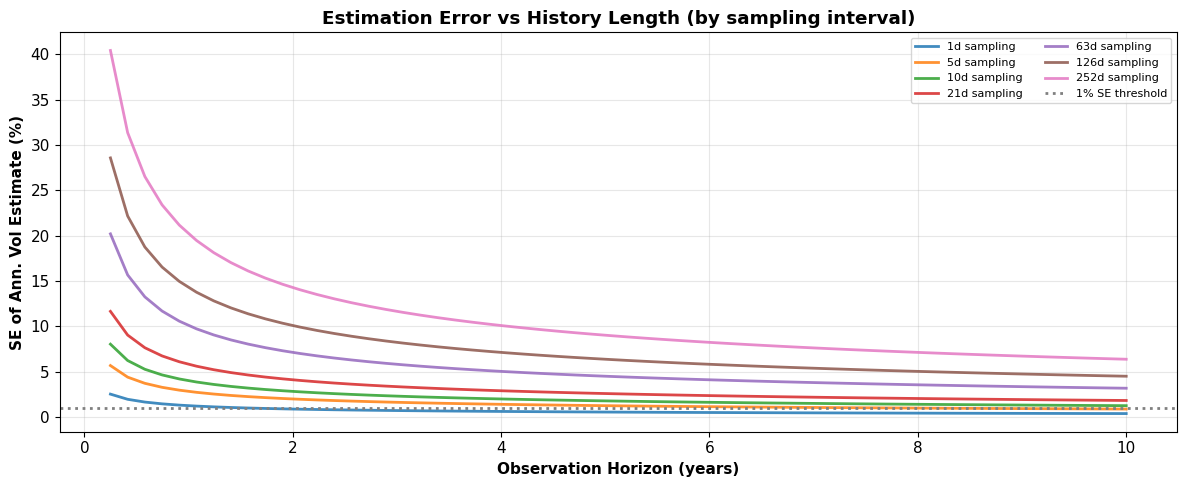

In [5]:

# ── 2D: Square-root-of-time scaling law ──────────────────────────────────────
horizons  = np.arange(1, 253)
daily_vol = TRUE_VOL

fig2d, ax = plt.subplots(figsize=(12, 5))
ax.plot(horizons, daily_vol * np.sqrt(horizons) * 100, color='steelblue',
        linewidth=2.5, label='σ × √T  (IID assumption)')
ax.axvline(252, color='red', linestyle='--', alpha=0.7, label='1 year (252 days)')
key_h  = [1, 5, 21, 63, 252]
key_v  = [daily_vol * np.sqrt(h) * 100 for h in key_h]
key_lb = ['1d', '1w', '1m', '3m', '1y']
ax.scatter(key_h, key_v, s=80, color='red', zorder=5)
for h, v, lbl in zip(key_h, key_v, key_lb):
    ax.annotate(f'{lbl}\n{v:.1f}%', (h, v), textcoords='offset points',
                xytext=(8, 4), fontsize=9)
ax.set_xlabel('Horizon (days)')
ax.set_ylabel('Volatility (%)')
ax.set_title('Square-Root-of-Time Scaling')
ax.legend()
plt.tight_layout()
plt.show()

# ── Plotly 3D: Vol estimation standard error — sampling freq × horizon ────────
# Under IID Normal returns with N = H/freq observations:
#   SE(σ_ann) = σ_ann / √(2N)  where  N = H / freq
# This shows the core trade-off: high-freq data OR long history reduces estimation error.

sigma_ann  = TRUE_VOL * np.sqrt(252) * 100      # true annualised vol in %
freqs_3d   = np.array([1, 5, 10, 21, 63, 126, 252])  # sampling intervals in days
horizons3  = np.linspace(63, 2520, 60)           # 3 months → 10 years of data

F3, H3     = np.meshgrid(freqs_3d, horizons3, indexing='ij')  # (7, 60)
N_periods  = H3 / F3                             # number of observations
se_ann     = sigma_ann / np.sqrt(2 * N_periods)  # SE of annualised vol estimate (%)

# 2D: SE curves for a few key frequencies
fig2d2, ax2 = plt.subplots(figsize=(12, 5))
for fi, f in enumerate(freqs_3d):
    n = horizons3 / f
    se = sigma_ann / np.sqrt(2 * n)
    lbl = f'{f}d sampling'
    ax2.plot(horizons3 / 252, se, label=lbl, alpha=0.85)
ax2.axhline(1.0, color='grey', linestyle=':', label='1% SE threshold')
ax2.set_xlabel('Observation Horizon (years)')
ax2.set_ylabel('SE of Ann. Vol Estimate (%)')
ax2.set_title('Estimation Error vs History Length (by sampling interval)')
ax2.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

# 3D surface
fig3d = go.Figure(go.Surface(
    x=np.log10(F3),
    y=H3 / 252,          # convert to years for readability
    z=se_ann,
    colorscale='RdYlGn',
    reversescale=True,
    colorbar=dict(title='SE of σ_ann (%)'),
    hovertemplate=(
        'Sampling=%{customdata}d<br>'
        'Horizon=%{y:.1f}yr<br>'
        'SE=%{z:.2f}%<extra></extra>'
    ),
    customdata=F3,
))
fig3d.update_layout(
    title=(
        '3D: Vol Estimation Standard Error — Sampling Interval × Observation Horizon<br>'
        '<sup>SE(σ_ann) = σ_ann / √(2N),  N = horizon/freq  '
        '— green = precise, red = noisy</sup>'
    ),
    scene=dict(
        xaxis=dict(
            title='Sampling Interval',
            tickvals=np.log10(freqs_3d).tolist(),
            ticktext=[f'{f}d' for f in freqs_3d],
        ),
        yaxis_title='Observation Horizon (years)',
        zaxis_title='SE of Ann. Vol (%)',
        camera=dict(eye=dict(x=1.6, y=-1.6, z=0.9)),
    ),
    height=650, width=1050,
    margin=dict(l=0, r=0, t=80, b=0),
)
fig3d.show()


---

# Part II — Historical (Close-to-Close) Volatility

## 2.1 Definition

The simplest and most widely used volatility estimator is the **rolling standard deviation of log returns**:

$$\hat{\sigma}_t = \sqrt{\frac{1}{n-1} \sum_{i=t-n+1}^{t} (r_i - \bar{r})^2}$$

where $\bar{r} = \frac{1}{n}\sum r_i$ is the sample mean over the window.

**In practice**, since daily means are near zero and estimating the mean adds noise, the **zero-mean version** is often preferred:

$$\hat{\sigma}_t^{\text{zero-mean}} = \sqrt{\frac{1}{n} \sum_{i=t-n+1}^{t} r_i^2}$$

This is actually a **more efficient estimator** when the true drift is small — estimating the mean from only $n$ points adds estimation error that outweighs the bias correction.

## 2.2 Window Length Trade-off

| Short window (e.g. 5d) | Long window (e.g. 60d) |
|------------------------|------------------------|
| Responsive to changes | Slow to react |
| Noisy, jumpy | Smooth, stable |
| Good for recent spikes | Good for baseline level |

This is the fundamental **bias-variance trade-off** in volatility estimation.

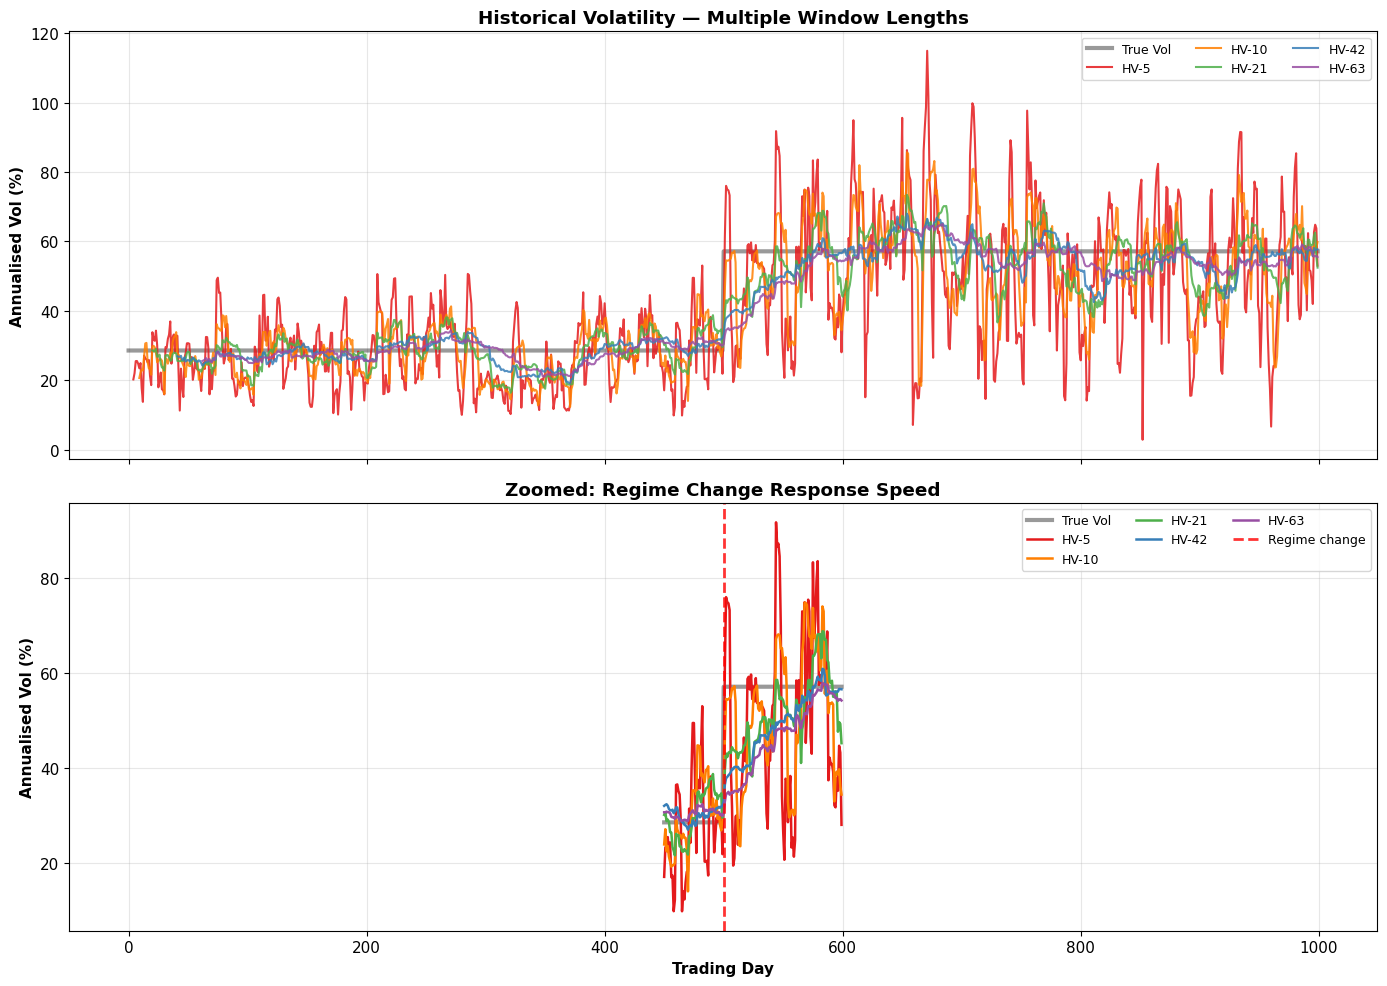

In [6]:
ANN = np.sqrt(252)   # annualisation factor

def hist_vol(rets, window, zero_mean=False):
    """Rolling historical volatility (annualised)."""
    s = pd.Series(rets)
    if zero_mean:
        rv = np.sqrt(s.pow(2).rolling(window).mean())
    else:
        rv = s.rolling(window).std()
    return rv.values * ANN

# ── Multiple windows ──────────────────────────────────────────────────────────
windows = [5, 10, 21, 42, 63]
colors  = ['#e41a1c','#ff7f00','#4daf4a','#377eb8','#984ea3']
true_ann = vol_path * ANN * 100

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

ax = axes[0]
ax.plot(t, true_ann, 'k-', linewidth=3, alpha=0.4, label='True Vol')
for w, col in zip(windows, colors):
    hv = hist_vol(log_rets, w) * 100
    ax.plot(t, hv, color=col, linewidth=1.5, alpha=0.85, label=f'HV-{w}')
ax.set_ylabel('Annualised Vol (%)')
ax.set_title('Historical Volatility — Multiple Window Lengths')
ax.legend(ncol=3, fontsize=9)

# Zoom into regime-change zone
ax2 = axes[1]
z = slice(450, 600)
ax2.plot(t[z], true_ann[z], 'k-', linewidth=3, alpha=0.4, label='True Vol')
for w, col in zip(windows, colors):
    hv = hist_vol(log_rets, w) * 100
    ax2.plot(t[z], hv[z], color=col, linewidth=1.8, label=f'HV-{w}')
ax2.axvline(500, color='red', linestyle='--', alpha=0.8, label='Regime change')
ax2.set_title('Zoomed: Regime Change Response Speed')
ax2.set_xlabel('Trading Day')
ax2.set_ylabel('Annualised Vol (%)')
ax2.legend(ncol=3, fontsize=9)

plt.tight_layout()
plt.show()

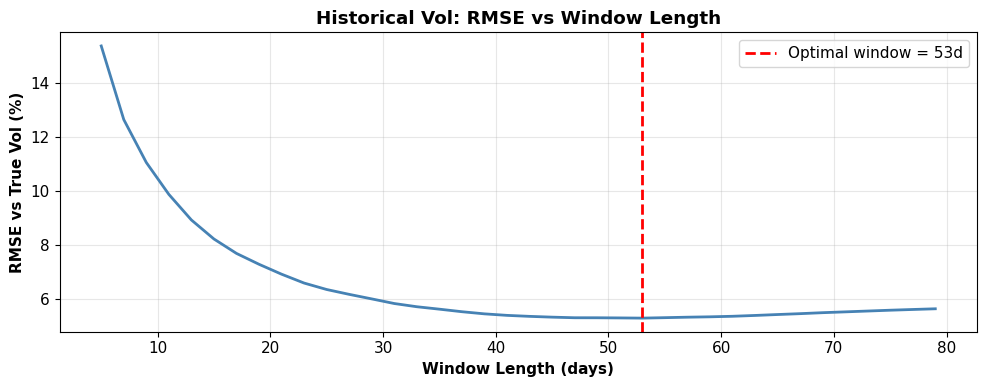

Optimal window: 53 days  |  RMSE: 5.298%


In [7]:
# ── Plotly 3D: HV estimate surface — time × window ───────────────────────────
win_range  = np.arange(5, 80, 2)
vol_surface = np.zeros((len(win_range), n_days))

for i, w in enumerate(win_range):
    hv = hist_vol(log_rets, w)
    vol_surface[i, :] = np.nan_to_num(hv * 100, nan=0.0)

# Downsample time axis for a smoother surface (every 5th day)
t_ds  = t[::5]
vs_ds = vol_surface[:, ::5]
W_3d, T_3d = np.meshgrid(win_range, t_ds, indexing='ij')

fig = go.Figure(go.Surface(
    x=T_3d, y=W_3d, z=vs_ds,
    colorscale='RdYlGn',
    reversescale=True,
    colorbar=dict(title='HV (%)'),
    hovertemplate='Day=%{x}<br>Window=%{y}d<br>Vol=%{z:.1f}%<extra></extra>',
))
fig.update_layout(
    title='3D: Historical Volatility Surface  (time × window → vol estimate)',
    scene=dict(
        xaxis_title='Time (days)',
        yaxis_title='Window Length (days)',
        zaxis_title='HV Estimate (%)',
        camera=dict(eye=dict(x=1.5, y=-1.5, z=0.9)),
        bgcolor='white',
    ),
    height=650, width=1000,
    margin=dict(l=0, r=0, t=60, b=0),
)
fig.show()

# ── 2D: RMSE vs window length ─────────────────────────────────────────────────
rmse_list = []
for w in win_range:
    hv    = hist_vol(log_rets, w) * 100
    valid = ~np.isnan(hv)
    rmse_list.append(np.sqrt(np.mean((hv[valid] - true_ann[valid])**2)))

best_w = win_range[np.argmin(rmse_list)]
plt.figure(figsize=(10, 4))
plt.plot(win_range, rmse_list, color='steelblue', linewidth=2)
plt.axvline(best_w, color='red', linestyle='--', label=f'Optimal window = {best_w}d')
plt.xlabel('Window Length (days)')
plt.ylabel('RMSE vs True Vol (%)')
plt.title('Historical Vol: RMSE vs Window Length')
plt.legend()
plt.tight_layout()
plt.show()
print(f'Optimal window: {best_w} days  |  RMSE: {min(rmse_list):.3f}%')

---

# Part III — Range-Based Volatility Estimators

## Why Range-Based?

The close-to-close estimator uses **only two data points per day** — open and close. It throws away the information in the intraday high and low. Range-based estimators exploit the full OHLC bar.

**Key intuition**: The range $H - L$ is a sufficient statistic for volatility if prices follow Brownian motion. Parkinson (1980) showed that the log high-low range is **5x more efficient** than the close-to-close estimator at equal sample size.

---

## 3.1 Parkinson Estimator (1980)

Uses only the high-low range. Assumes zero drift (reasonable for short windows).

$$\hat{\sigma}^2_{\text{Park}} = \frac{1}{4 \ln 2} \cdot \frac{1}{n} \sum_{i=1}^{n} \left[\ln\!\left(\frac{H_i}{L_i}\right)\right]^2$$

**Efficiency vs close-to-close**: 5.2x

---

## 3.2 Garman-Klass Estimator (1980)

Adds the open-close component to the Parkinson formula.

$$\hat{\sigma}^2_{\text{GK}} = \frac{1}{n}\sum_{i=1}^{n} \left[ \frac{1}{2}\left(\ln\frac{H_i}{L_i}\right)^2 - (2\ln 2 - 1)\left(\ln\frac{C_i}{O_i}\right)^2 \right]$$

**Efficiency vs close-to-close**: 7.4x

---

## 3.3 Rogers-Satchell Estimator (1991)

Handles non-zero drift correctly — the only single-period estimator that is drift-independent.

$$\hat{\sigma}^2_{\text{RS}} = \frac{1}{n}\sum_{i=1}^{n} \left[ \ln\frac{H_i}{C_i}\cdot\ln\frac{H_i}{O_i} + \ln\frac{L_i}{C_i}\cdot\ln\frac{L_i}{O_i} \right]$$

**Efficiency vs close-to-close**: 6x, unbiased under drift

---

## 3.4 Yang-Zhang Estimator (2000)

The most sophisticated single-frequency estimator. Handles both drift and **overnight gaps** (the jump from yesterday's close to today's open, which open-to-close estimators miss entirely).

$$\hat{\sigma}^2_{\text{YZ}} = \hat{\sigma}^2_{\text{overnight}} + k \cdot \hat{\sigma}^2_{\text{open-to-close}} + (1-k)\cdot \hat{\sigma}^2_{\text{RS}}$$

where $k = \frac{0.34}{1.34 + (n+1)/(n-1)}$ is the optimal weight.

**Efficiency vs close-to-close**: 14x (highest of all single-frequency estimators)

---

## Comparison Table

| Estimator | Year | Uses | Efficiency | Drift? | Overnight? |
|-----------|------|------|------------|--------|------------|
| Close-to-Close | — | C | 1x | ✓ | ✗ |
| Parkinson | 1980 | H, L | 5.2x | ✗ | ✗ |
| Garman-Klass | 1980 | O, H, L, C | 7.4x | ✗ | ✗ |
| Rogers-Satchell | 1991 | O, H, L, C | 6x | ✓ | ✗ |
| Yang-Zhang | 2000 | O, H, L, C + prev C | 14x | ✓ | ✓ |

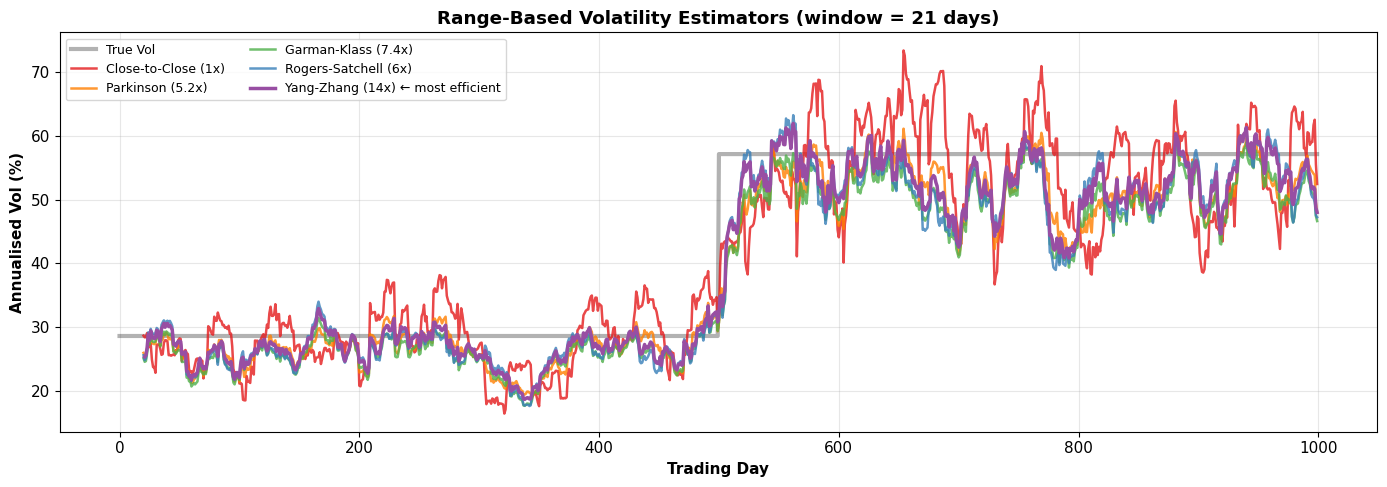

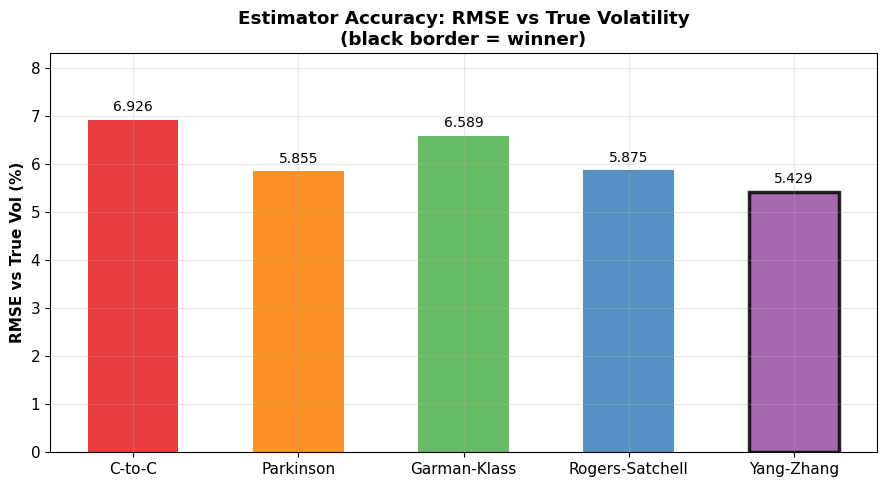


RMSE comparison (window=21d):
  C-to-C              : 6.9258%
  Parkinson           : 5.8548%
  Garman-Klass        : 6.5892%
  Rogers-Satchell     : 5.8748%
  Yang-Zhang          : 5.4288%


In [8]:

def parkinson(H, L, window):
    hl = np.log(H / L)
    var = pd.Series(hl**2).rolling(window).mean() / (4 * np.log(2))
    return np.sqrt(var.values) * ANN

def garman_klass(O, H, L, C, window):
    hl = np.log(H / L)
    co = np.log(C / O)
    daily = 0.5 * hl**2 - (2*np.log(2) - 1) * co**2
    var = pd.Series(daily).rolling(window).mean()
    return np.sqrt(var.values.clip(0)) * ANN

def rogers_satchell(O, H, L, C, window):
    hc = np.log(H / C)
    ho = np.log(H / O)
    lc = np.log(L / C)
    lo = np.log(L / O)
    daily = hc * ho + lc * lo
    var = pd.Series(daily).rolling(window).mean()
    return np.sqrt(var.values.clip(0)) * ANN

def yang_zhang(O, H, L, C, window):
    """Yang-Zhang estimator with overnight gap correction."""
    n  = window
    k  = 0.34 / (1.34 + (n + 1) / (n - 1))
    oc = np.log(O[1:] / C[:-1])
    co = np.log(C[1:] / O[1:])
    hc = np.log(H[1:] / C[1:])
    ho = np.log(H[1:] / O[1:])
    lc = np.log(L[1:] / C[1:])
    lo = np.log(L[1:] / O[1:])
    rs = hc * ho + lc * lo

    s = pd.Series
    var_oc = s(oc).rolling(window).var()
    var_co = s(co).rolling(window).var()
    var_rs = s(rs).rolling(window).mean()
    var_yz = var_oc + k * var_co + (1 - k) * var_rs

    out = np.concatenate([[np.nan], var_yz.values])
    return np.sqrt(out.clip(0)) * ANN

# ── Compute all estimators at w=21 ───────────────────────────────────────────
w = 21
hv_cc  = hist_vol(log_rets, w)
hv_pk  = parkinson(H, L, w)
hv_gk  = garman_klass(O, H, L, C, w)
hv_rs  = rogers_satchell(O, H, L, C, w)
hv_yz  = yang_zhang(O, H, L, C, w)

estimators = {
    'C-to-C': hv_cc, 'Parkinson': hv_pk,
    'Garman-Klass': hv_gk, 'Rogers-Satchell': hv_rs, 'Yang-Zhang': hv_yz
}
rmse_vals = []
for name, est in estimators.items():
    e = est * 100
    valid = ~np.isnan(e)
    rmse_vals.append(np.sqrt(np.mean((e[valid] - true_ann[valid])**2)))

# ── Plot 1: time-series comparison (standalone figure) ───────────────────────
fig1, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(t, true_ann,    'k-',  linewidth=3, alpha=0.3, label='True Vol')
ax1.plot(t, hv_cc * 100, color='#e41a1c', linewidth=1.8, alpha=0.8, label='Close-to-Close (1x)')
ax1.plot(t, hv_pk * 100, color='#ff7f00', linewidth=1.8, alpha=0.8, label='Parkinson (5.2x)')
ax1.plot(t, hv_gk * 100, color='#4daf4a', linewidth=1.8, alpha=0.8, label='Garman-Klass (7.4x)')
ax1.plot(t, hv_rs * 100, color='#377eb8', linewidth=1.8, alpha=0.8, label='Rogers-Satchell (6x)')
ax1.plot(t, hv_yz * 100, color='#984ea3', linewidth=2.5, label='Yang-Zhang (14x) ← most efficient')
ax1.set_title(f'Range-Based Volatility Estimators (window = {w} days)')
ax1.set_ylabel('Annualised Vol (%)')
ax1.set_xlabel('Trading Day')
ax1.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

# ── Plot 2: RMSE bar chart (separate figure — no shared x-axis) ──────────────
bar_colors = ['#e41a1c','#ff7f00','#4daf4a','#377eb8','#984ea3']
fig2, ax2 = plt.subplots(figsize=(9, 5))
bars = ax2.bar(list(estimators.keys()), rmse_vals, color=bar_colors, alpha=0.85, width=0.55)
ax2.bar_label(bars, fmt='%.3f', padding=4, fontsize=10)
best_idx = int(np.argmin(rmse_vals))
bars[best_idx].set_edgecolor('black')
bars[best_idx].set_linewidth(2.5)
ax2.set_ylabel('RMSE vs True Vol (%)')
ax2.set_title('Estimator Accuracy: RMSE vs True Volatility\n(black border = winner)')
ax2.set_ylim(0, max(rmse_vals) * 1.20)
plt.tight_layout()
plt.show()

print(f'\nRMSE comparison (window={w}d):')
for name, rmse in zip(estimators.keys(), rmse_vals):
    print(f'  {name:<20}: {rmse:.4f}%')


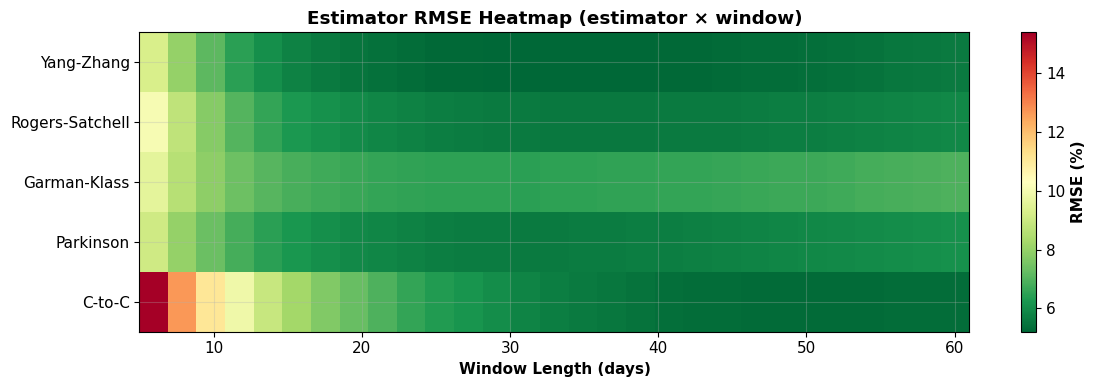

In [9]:

# ── 3D: RMSE surface across estimators and window lengths ────────────────────
win_range2 = np.arange(5, 63, 2)
est_names  = ['C-to-C', 'Parkinson', 'Garman-Klass', 'Rogers-Satchell', 'Yang-Zhang']
rmse_grid  = np.zeros((len(est_names), len(win_range2)))

for j, w_ in enumerate(win_range2):
    ests = [
        hist_vol(log_rets, w_),
        parkinson(H, L, w_),
        garman_klass(O, H, L, C, w_),
        rogers_satchell(O, H, L, C, w_),
        yang_zhang(O, H, L, C, w_),
    ]
    for i, est in enumerate(ests):
        e = est * 100
        valid = ~np.isnan(e)
        rmse_grid[i, j] = np.sqrt(np.mean((e[valid] - true_ann[valid])**2))

# 2D heatmap companion
fig2d, ax2d = plt.subplots(figsize=(12, 4))
im = ax2d.imshow(rmse_grid, aspect='auto', cmap='RdYlGn_r', origin='lower',
                 extent=[win_range2[0], win_range2[-1], -0.5, len(est_names)-0.5])
ax2d.set_yticks(range(len(est_names))); ax2d.set_yticklabels(est_names)
ax2d.set_xlabel('Window Length (days)'); ax2d.set_title('Estimator RMSE Heatmap (estimator × window)')
plt.colorbar(im, ax=ax2d, label='RMSE (%)'); plt.tight_layout(); plt.show()

# 3D Plotly surface
E_idx = np.arange(len(est_names))
E_grid, W_grid2 = np.meshgrid(E_idx, win_range2, indexing='ij')

fig3d = go.Figure(go.Surface(
    x=E_grid.astype(float),
    y=W_grid2.astype(float),
    z=rmse_grid,
    colorscale='RdYlGn_r',
    colorbar=dict(title='RMSE (%)'),
    hovertemplate='Estimator idx=%{x:.0f}<br>Window=%{y}d<br>RMSE=%{z:.3f}%<extra></extra>',
))
fig3d.update_layout(
    title='3D: Estimator RMSE Surface  (estimator × window → accuracy)',
    scene=dict(
        xaxis=dict(title='Estimator', tickvals=list(E_idx), ticktext=est_names),
        yaxis_title='Window Length (days)',
        zaxis_title='RMSE vs True Vol (%)',
        camera=dict(eye=dict(x=1.6, y=-1.6, z=1.0)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=60, b=0),
)
fig3d.show()


---

# Part IV — Realized Volatility from High-Frequency Data

## 4.1 Motivation

All the estimators above use daily OHLC data. But intraday tick data (every minute, every second) contains far more information. **Realized Volatility (RV)** exploits this by summing up squared intraday returns.

## 4.2 Definition

Given $M$ intraday log returns $r_{t,1}, r_{t,2}, \ldots, r_{t,M}$ within day $t$:

$$RV_t = \sum_{j=1}^{M} r_{t,j}^2$$

As the sampling frequency $M \to \infty$, $RV_t$ converges to the **quadratic variation** of the continuous-time log price process — this is a model-free, nonparametric measure of realized variance.

Under GBM: $\mathbb{E}[RV_t] = \sigma_t^2$ (one day's integrated variance).

## 4.3 Microstructure Noise Problem

In practice, **sampling too frequently** introduces **microstructure noise** — bid-ask bounces, price discretisation, and other market frictions that add spurious variation. The RV overestimates true volatility.

**Solution**: Sample at an intermediate frequency (typically 5-minute returns for equities) — the **"5-minute rule"**.

## 4.4 Realized Kernel Estimator

A more sophisticated approach weights returns to correct for microstructure noise:
$$RK = \sum_{h=-H}^{H} k\!\left(\frac{h}{H+1}\right) \Gamma_h, \quad \Gamma_h = \sum_{j} r_j r_{j-|h|}$$
where $k(\cdot)$ is a kernel function (e.g., Parzen) and $\Gamma_h$ is the lag-$h$ autocovariance of intraday returns.

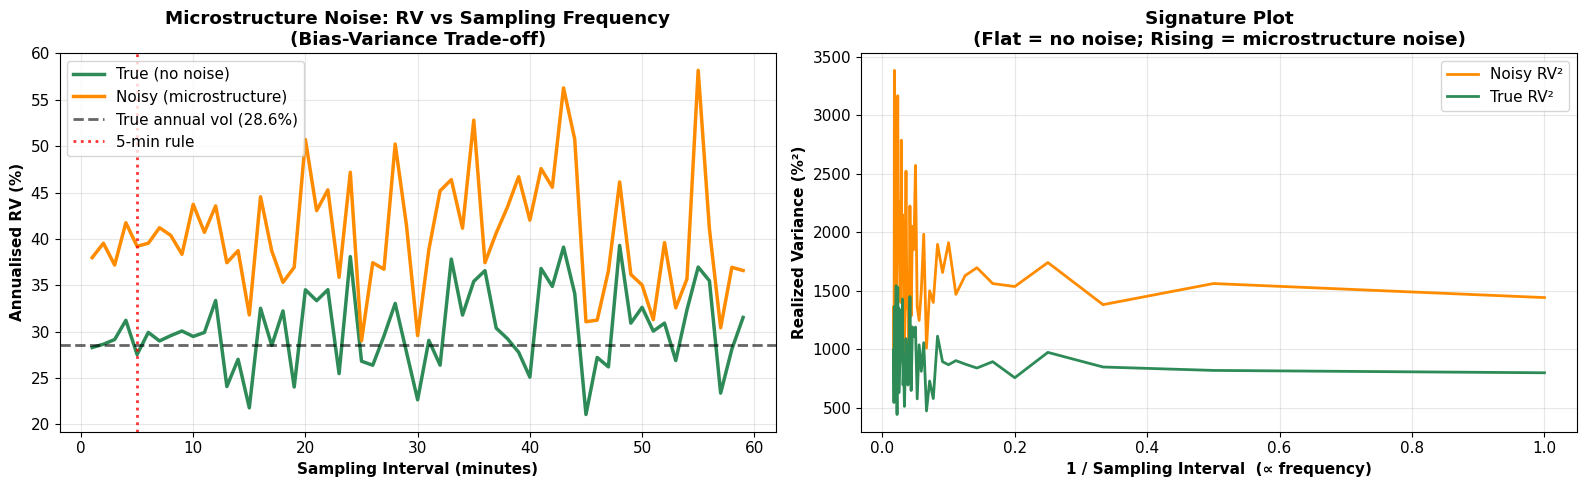

Realized Volatility (1-day simulation):
  True vol (annualised)    : 28.57%
  RV at 1-min (noisy)      : 37.98%  (+33% bias)
  RV at 5-min (noisy)      : 39.21%
  RV at 30-min (noisy)     : 29.57%


In [10]:
np.random.seed(0)

# ── Simulate intraday prices for one representative day ───────────────────────
# We use M = 390 minutes (NYSE trading day)
M_full   = 390    # 1-min bars
sigma_day = TRUE_VOL

# True 1-min log returns
true_intraday = np.random.normal(0, sigma_day / np.sqrt(M_full), M_full)

# Add microstructure noise (bid-ask bounce ~ N(0, noise_sigma))
noise_sigma   = sigma_day / np.sqrt(M_full) * 0.8   # noise ≈ 80% of 1-min move
noisy_intraday = true_intraday + np.random.normal(0, noise_sigma, M_full)

def realized_vol(returns, subsample_freq=1):
    """Realized variance at a given subsampling frequency, annualised."""
    sub = returns[::subsample_freq]
    RV  = np.sum(sub**2) * subsample_freq   # scale back to full-day var
    return np.sqrt(RV * 252)

# Compute RV at many sampling frequencies
freqs     = np.arange(1, 60)   # 1-min to 60-min
rv_true   = [realized_vol(true_intraday,   f) for f in freqs]
rv_noisy  = [realized_vol(noisy_intraday,  f) for f in freqs]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.plot(freqs, np.array(rv_true)  * 100, 'seagreen',   linewidth=2.5, label='True (no noise)')
ax.plot(freqs, np.array(rv_noisy) * 100, 'darkorange',  linewidth=2.5, label='Noisy (microstructure)')
ax.axhline(TRUE_VOL * np.sqrt(252) * 100, color='k', linestyle='--',
           alpha=0.6, label=f'True annual vol ({TRUE_VOL*np.sqrt(252):.1%})')
ax.axvline(5, color='red', linestyle=':', alpha=0.8, label='5-min rule')
ax.set_xlabel('Sampling Interval (minutes)')
ax.set_ylabel('Annualised RV (%)')
ax.set_title('Microstructure Noise: RV vs Sampling Frequency\n(Bias-Variance Trade-off)')
ax.legend()

# Signature plot (Variance vs 1/freq)
ax2 = axes[1]
ax2.plot(1.0 / freqs, np.array(rv_noisy)**2 * 100**2, 'darkorange', linewidth=2, label='Noisy RV²')
ax2.plot(1.0 / freqs, np.array(rv_true)**2  * 100**2, 'seagreen',   linewidth=2, label='True RV²')
ax2.set_xlabel('1 / Sampling Interval  (∝ frequency)')
ax2.set_ylabel('Realized Variance (%²)')
ax2.set_title('Signature Plot\n(Flat = no noise; Rising = microstructure noise)')
ax2.legend()

plt.tight_layout()
plt.show()

print('Realized Volatility (1-day simulation):')
print(f'  True vol (annualised)    : {TRUE_VOL * np.sqrt(252):.2%}')
print(f'  RV at 1-min (noisy)      : {realized_vol(noisy_intraday, 1):.2%}  (+{(realized_vol(noisy_intraday,1)/TRUE_VOL/np.sqrt(252)-1):.0%} bias)')
print(f'  RV at 5-min (noisy)      : {realized_vol(noisy_intraday, 5):.2%}')
print(f'  RV at 30-min (noisy)     : {realized_vol(noisy_intraday, 30):.2%}')

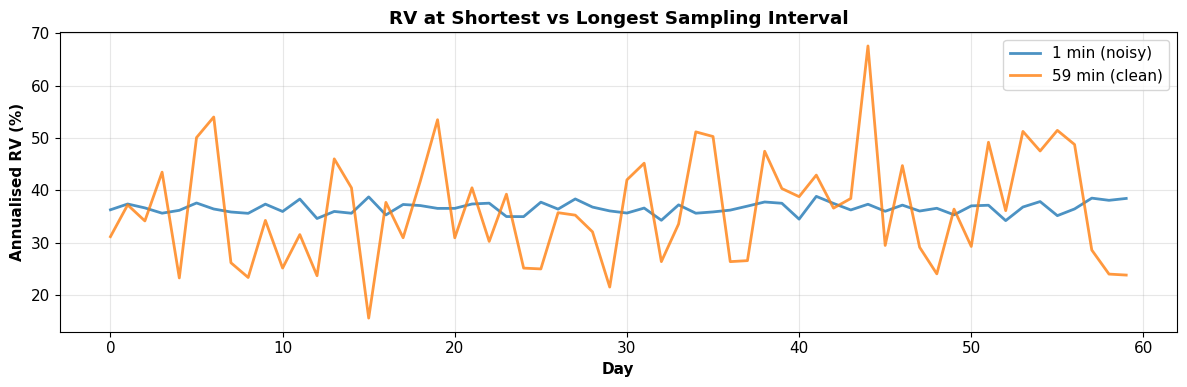

In [11]:

# ── 3D: Realized variance as a function of both time and sampling frequency ───
np.random.seed(1)
n_sim_days = 60

rv_matrix = np.zeros((n_sim_days, len(freqs)))
for d in range(n_sim_days):
    true_r  = np.random.normal(0, vol_path[d] / np.sqrt(M_full), M_full)
    noise_r = true_r + np.random.normal(0, noise_sigma, M_full)
    for j, f in enumerate(freqs):
        rv_matrix[d, j] = realized_vol(noise_r, f) * 100

# 2D companion: RV at extreme frequencies over time
fig2d, ax2d = plt.subplots(figsize=(12, 4))
ax2d.plot(rv_matrix[:, 0],  label=f'{freqs[0]} min (noisy)', alpha=0.8)
ax2d.plot(rv_matrix[:, -1], label=f'{freqs[-1]} min (clean)', alpha=0.8)
ax2d.set_xlabel('Day'); ax2d.set_ylabel('Annualised RV (%)')
ax2d.set_title('RV at Shortest vs Longest Sampling Interval'); ax2d.legend()
plt.tight_layout(); plt.show()

# 3D Plotly surface
D_vals  = np.arange(n_sim_days)
D_grid, Fr_grid = np.meshgrid(D_vals, freqs, indexing='ij')

fig3d = go.Figure(go.Surface(
    x=D_grid.astype(float),
    y=Fr_grid.astype(float),
    z=rv_matrix,
    colorscale='plasma',
    colorbar=dict(title='RV (%)'),
    hovertemplate='Day=%{x:.0f}<br>Freq=%{y} min<br>RV=%{z:.1f}%<extra></extra>',
))
fig3d.update_layout(
    title='3D: Realized Volatility — Day × Sampling Frequency Surface',
    scene=dict(
        xaxis_title='Day',
        yaxis_title='Sampling Interval (min)',
        zaxis_title='Annualised RV (%)',
        camera=dict(eye=dict(x=1.5, y=-1.5, z=0.9)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=60, b=0),
)
fig3d.show()


---

# Part V — EWMA / RiskMetrics Volatility

## 5.1 Problem with Rolling Windows

Historical volatility with a fixed window weights all observations equally: the return from 20 days ago matters exactly as much as yesterday's return. This is clearly suboptimal — recent information should matter more.

## 5.2 Exponentially Weighted Moving Average (EWMA)

EWMA applies exponentially decaying weights, so recent returns dominate:

$$\hat{\sigma}_t^2 = (1-\lambda) r_{t-1}^2 + \lambda \hat{\sigma}_{t-1}^2$$

- $\lambda \in (0,1)$ is the **decay factor** (persistence parameter)
- Equivalent effective window: $w_{\text{eff}} = \frac{1}{1-\lambda}$
- **J.P. Morgan RiskMetrics standard**: $\lambda = 0.94$ for daily data

**Recursive expansion:**
$$\hat{\sigma}_t^2 = (1-\lambda) \sum_{k=1}^{\infty} \lambda^{k-1} r_{t-k}^2$$

Weights decay geometrically: weight on $r_{t-k}$ is $(1-\lambda)\lambda^{k-1}$.

## 5.3 EWMA vs Rolling Window

| Property | Rolling Window | EWMA |
|----------|---------------|------|
| Recency weighting | Equal | Exponential |
| Ghost effects | Yes — old outlier drops off a cliff | No — old returns fade gradually |
| Parameters | Window $n$ | $\lambda$ |
| Stationarity | Requires data | Self-initialising |

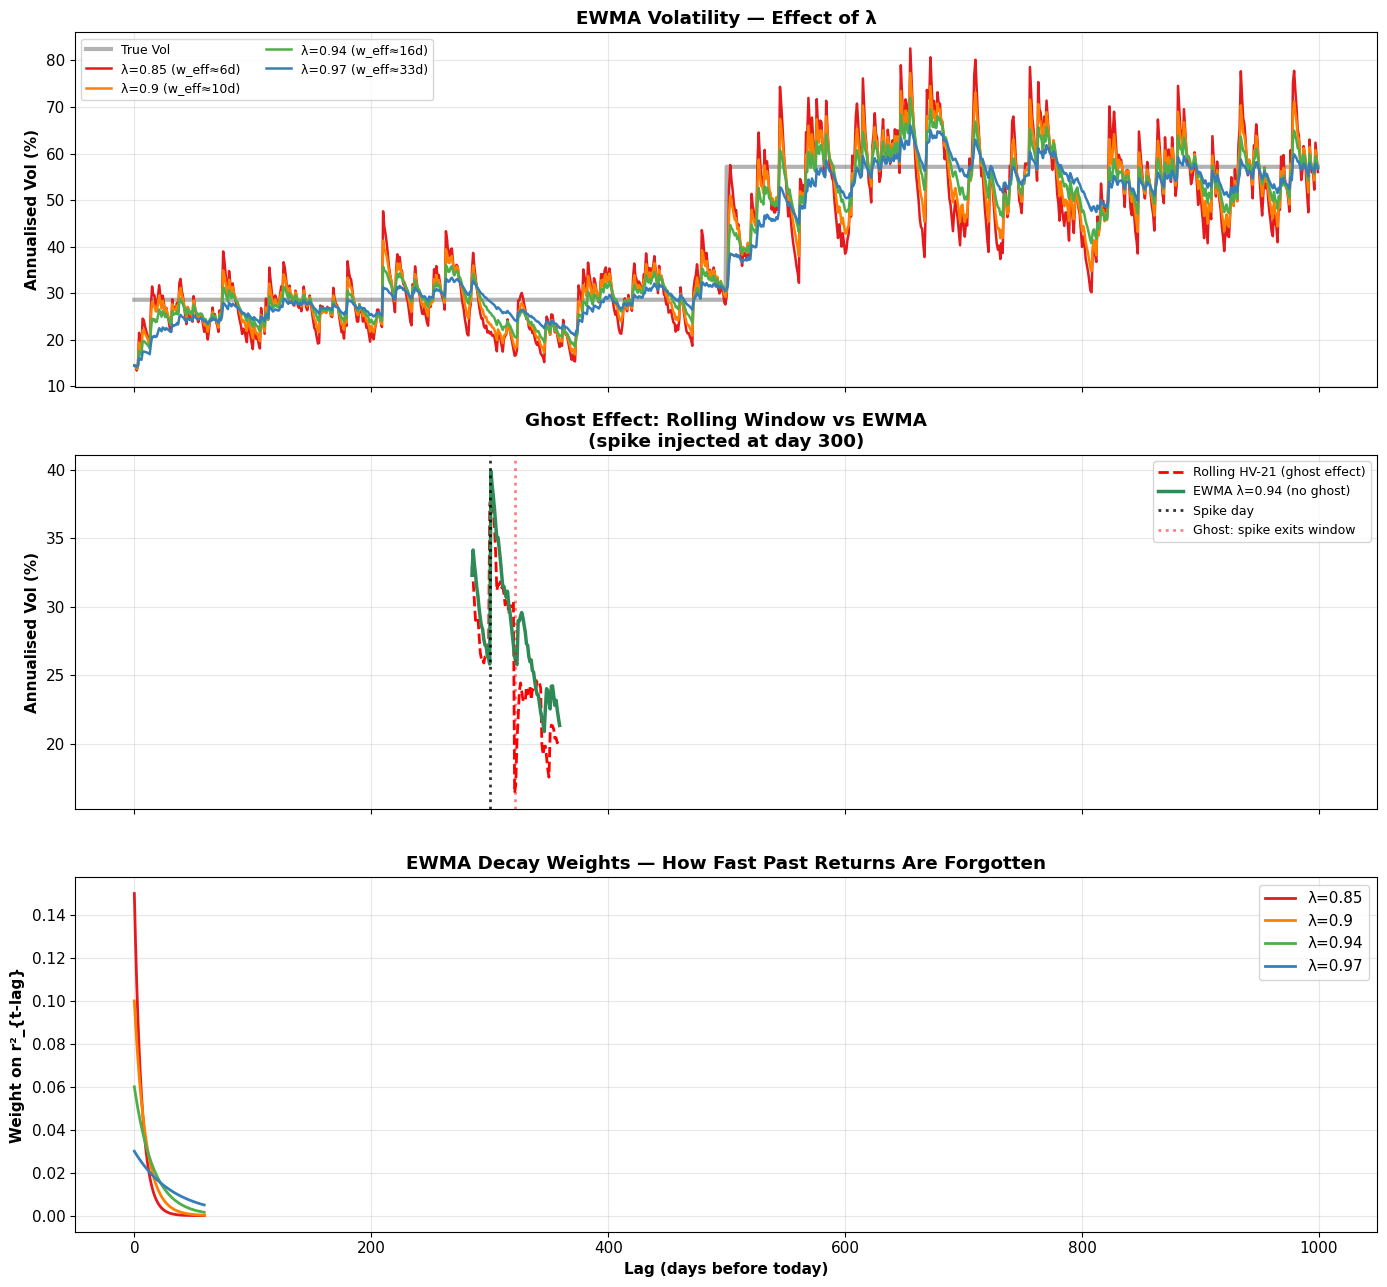

In [12]:
def ewma_vol(rets, lam):
    """EWMA variance (RiskMetrics), annualised."""
    var = np.zeros(len(rets))
    var[0] = rets[0]**2
    for i in range(1, len(rets)):
        var[i] = (1 - lam) * rets[i-1]**2 + lam * var[i-1]
    return np.sqrt(var) * ANN

lambdas = [0.85, 0.90, 0.94, 0.97]
cols    = ['#e41a1c','#ff7f00','#4daf4a','#377eb8']

fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)

# All EWMA curves
ax = axes[0]
ax.plot(t, true_ann, 'k-', linewidth=3, alpha=0.3, label='True Vol')
for lam, col in zip(lambdas, cols):
    ev = ewma_vol(log_rets, lam) * 100
    w_eff = int(1 / (1 - lam))
    ax.plot(t, ev, color=col, linewidth=1.8, label=f'λ={lam} (w_eff≈{w_eff}d)')
ax.set_title('EWMA Volatility — Effect of λ')
ax.set_ylabel('Annualised Vol (%)')
ax.legend(ncol=2, fontsize=9)

# Ghost effect demo: EWMA vs Rolling around a spike
# Inject a large return at day 300
rets_spike = log_rets.copy()
rets_spike[300] = 0.08   # large spike

ax2 = axes[1]
z = slice(285, 360)
ax2.plot(t[z], hist_vol(rets_spike, 21)[z]      * 100, color='red', linestyle='--',
         linewidth=2, label='Rolling HV-21 (ghost effect)')
ax2.plot(t[z], ewma_vol(rets_spike, 0.94)[z]     * 100, color='seagreen', linewidth=2.5,
         label='EWMA λ=0.94 (no ghost)')
ax2.axvline(300, color='k', linestyle=':', alpha=0.8, label='Spike day')
ax2.axvline(321, color='red', linestyle=':', alpha=0.5, label='Ghost: spike exits window')
ax2.set_title('Ghost Effect: Rolling Window vs EWMA\n(spike injected at day 300)')
ax2.set_ylabel('Annualised Vol (%)')
ax2.legend(fontsize=9)

# EWMA weights visualisation
ax3 = axes[2]
lags = np.arange(0, 60)
for lam, col in zip(lambdas, cols):
    weights = (1 - lam) * lam**lags
    ax3.plot(lags, weights, color=col, linewidth=2, label=f'λ={lam}')
ax3.set_xlabel('Lag (days before today)')
ax3.set_ylabel('Weight on r²_{t-lag}')
ax3.set_title('EWMA Decay Weights — How Fast Past Returns Are Forgotten')
ax3.legend()

plt.tight_layout()
plt.show()

---

# Part VI — GARCH(1,1): Theory & Implementation

## 6.1 Motivation — What EWMA Misses

EWMA is essentially GARCH(1,1) with the constraint $\alpha + \beta = 1$ (integrated GARCH). This implies:
- Volatility shocks **never decay** — the effect of a large return persists forever
- No **long-run mean** (unconditional variance is undefined)

Real volatility is **mean-reverting** — extreme volatility episodes eventually return to a baseline level. GARCH captures this.

## 6.2 GARCH(1,1) Model

**Return equation**: $r_t = \mu + \epsilon_t, \quad \epsilon_t = \sigma_t z_t, \quad z_t \sim \mathcal{N}(0,1)$

**Variance equation**:
$$\sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2$$

**Parameters:**
- $\omega > 0$: constant (baseline variance)
- $\alpha \geq 0$: **ARCH term** — sensitivity of variance to past squared shocks
- $\beta \geq 0$: **GARCH term** — persistence (how slowly variance decays)
- Stationarity requires $\alpha + \beta < 1$

## 6.3 Long-Run (Unconditional) Variance

$$\bar{\sigma}^2 = \frac{\omega}{1 - \alpha - \beta}$$

When $\alpha + \beta$ is close to 1 (high persistence), $\bar{\sigma}^2$ is very sensitive to $\omega$. This is the long-run level to which volatility mean-reverts.

## 6.4 Multi-Step Forecasting

The $h$-step-ahead conditional variance from time $t$:
$$\mathbb{E}_t[\sigma_{t+h}^2] = \bar{\sigma}^2 + (\alpha+\beta)^{h-1}(\sigma_{t+1}^2 - \bar{\sigma}^2)$$

The current variance gap $(\sigma_{t+1}^2 - \bar{\sigma}^2)$ decays geometrically at rate $(\alpha+\beta)$. The half-life of a shock is $\frac{\ln 0.5}{\ln(\alpha+\beta)}$ periods.

## 6.5 GARCH vs EWMA vs Rolling

| Model | Long-run mean | Persistence control | Optimal parameters |
|-------|--------------|--------------------|--------------------|
| Rolling HV | No | Window (implicit) | None |
| EWMA | No ($\alpha+\beta=1$) | $\lambda$ | Fixed (RiskMetrics) |
| GARCH(1,1) | Yes | $\alpha, \beta$ | MLE |

In [13]:

from scipy.optimize import minimize

# ── GARCH(1,1) from scratch ────────────────────────────────────────────────────

def garch_variance_path(rets, omega, alpha, beta):
    """Compute the GARCH(1,1) conditional variance path."""
    n = len(rets)
    sigma2 = np.zeros(n)
    sigma2[0] = np.var(rets)
    for i in range(1, n):
        sigma2[i] = omega + alpha * rets[i-1]**2 + beta * sigma2[i-1]
    return sigma2

def garch_log_likelihood(params, rets):
    """Negative log-likelihood for GARCH(1,1) (Gaussian errors)."""
    omega, alpha, beta = params
    # Hard constraint: stationarity (alpha+beta < 1) with buffer
    if omega <= 0 or alpha < 0 or beta < 0 or alpha + beta >= 0.9999:
        return 1e10
    sigma2 = garch_variance_path(rets, omega, alpha, beta)
    if np.any(sigma2 <= 0):
        return 1e10
    ll = -0.5 * np.sum(np.log(2 * np.pi * sigma2) + rets**2 / sigma2)
    return -ll

def fit_garch(rets):
    """Fit GARCH(1,1) via MLE — multi-start to avoid near-integrated local minima."""
    var0 = np.var(rets)
    # Tight bounds: alpha realistic (≤0.4 for financial data), beta≤0.97
    bounds = [(1e-8, None), (1e-6, 0.40), (1e-6, 0.97)]

    # Several starting points covering different persistence levels
    starts = [
        (0.06, 0.92),   # high persistence
        (0.10, 0.85),   # standard
        (0.15, 0.80),   # moderate
        (0.08, 0.88),   # between
    ]
    best_result, best_ll = None, np.inf
    for a0, b0 in starts:
        x0 = [var0 * (1 - a0 - b0), a0, b0]
        res = minimize(
            garch_log_likelihood, x0, args=(rets,),
            method='L-BFGS-B', bounds=bounds,
            options={'maxiter': 10000, 'ftol': 1e-14},
        )
        if res.fun < best_ll:
            best_ll = res.fun
            best_result = res

    return best_result.x

# Fit GARCH on the full return series
omega_hat, alpha_hat, beta_hat = fit_garch(log_rets)
sigma2_garch = garch_variance_path(log_rets, omega_hat, alpha_hat, beta_hat)
sigma_garch  = np.sqrt(sigma2_garch) * ANN * 100

long_run_vol  = np.sqrt(omega_hat / (1 - alpha_hat - beta_hat)) * ANN * 100
persistence   = alpha_hat + beta_hat
half_life     = np.log(0.5) / np.log(persistence)

print('GARCH(1,1) fitted parameters:')
print(f'  ω (omega)        = {omega_hat:.2e}')
print(f'  α (alpha)        = {alpha_hat:.4f}  ← sensitivity to shocks')
print(f'  β (beta)         = {beta_hat:.4f}  ← persistence')
print(f'  α + β            = {persistence:.4f}  ← total persistence (< 1 for stationarity)')
print(f'  Long-run vol     = {long_run_vol:.2f}%  annualised')
print(f'  Shock half-life  = {half_life:.1f} days')


GARCH(1,1) fitted parameters:
  ω (omega)        = 1.22e-06
  α (alpha)        = 0.0331  ← sensitivity to shocks
  β (beta)         = 0.9668  ← persistence
  α + β            = 0.9999  ← total persistence (< 1 for stationarity)
  Long-run vol     = 171.34%  annualised
  Shock half-life  = 6595.4 days


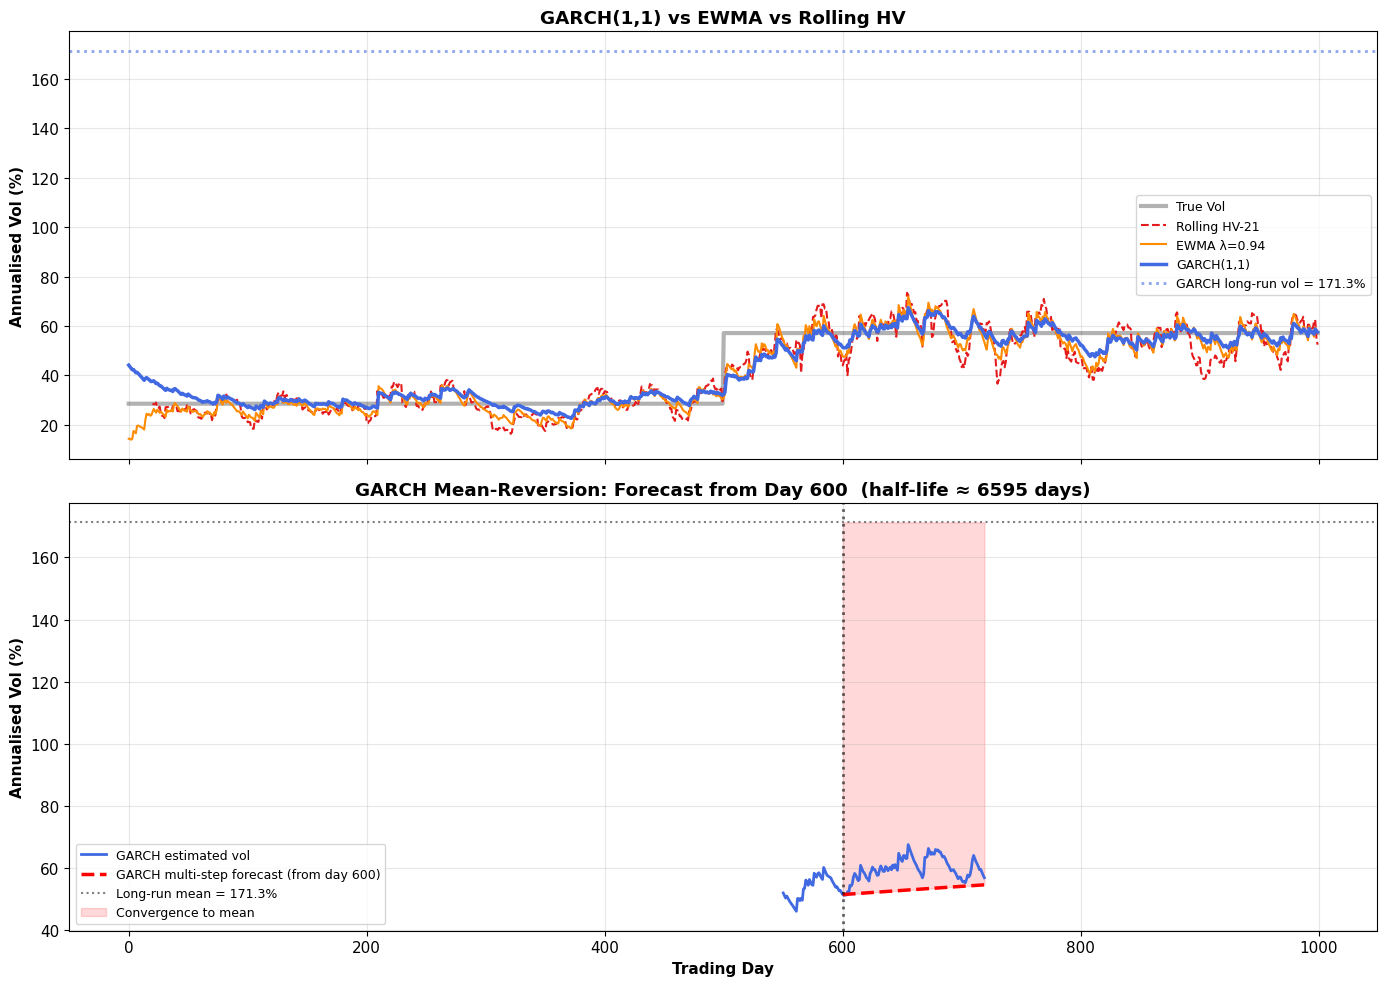

In [14]:
# ── Plot: GARCH vs all other estimators ──────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

ax = axes[0]
ax.plot(t, true_ann,            'k-',  linewidth=3, alpha=0.3, label='True Vol')
ax.plot(t, hist_vol(log_rets, 21)*100, color='#e41a1c', linestyle='--',
        linewidth=1.5, label='Rolling HV-21')
ax.plot(t, ewma_vol(log_rets, 0.94)*100, color='darkorange', linewidth=1.5,
        label='EWMA λ=0.94')
ax.plot(t, sigma_garch,         color='royalblue', linewidth=2.5, label='GARCH(1,1)')
ax.axhline(long_run_vol, color='royalblue', linestyle=':', alpha=0.6,
           label=f'GARCH long-run vol = {long_run_vol:.1f}%')
ax.set_title('GARCH(1,1) vs EWMA vs Rolling HV')
ax.set_ylabel('Annualised Vol (%)')
ax.legend(fontsize=9)

# Mean-reversion illustration: impulse forecast from a high-vol point
ax2 = axes[1]
t0          = 600   # start of high-vol regime
h_steps     = 120
sigma2_now  = sigma2_garch[t0]
long_run_var = omega_hat / (1 - alpha_hat - beta_hat)

forecast_var = np.array([
    long_run_var + (persistence**(h-1)) * (sigma2_now - long_run_var)
    for h in range(1, h_steps+1)
])
forecast_vol = np.sqrt(forecast_var) * ANN * 100
horizons_fcast = np.arange(t0, t0 + h_steps)

ax2.plot(t[t0-50:t0+h_steps], sigma_garch[t0-50:t0+h_steps],
         color='royalblue', linewidth=2, label='GARCH estimated vol')
ax2.plot(horizons_fcast, forecast_vol, 'r--', linewidth=2.5,
         label=f'GARCH multi-step forecast (from day {t0})')
ax2.axhline(long_run_vol, color='gray', linestyle=':', linewidth=1.5,
            label=f'Long-run mean = {long_run_vol:.1f}%')
ax2.axvline(t0, color='k', linestyle=':', alpha=0.6)
ax2.fill_between(horizons_fcast, forecast_vol, long_run_vol,
                 alpha=0.15, color='red', label='Convergence to mean')
ax2.set_title(f'GARCH Mean-Reversion: Forecast from Day {t0}  (half-life ≈ {half_life:.0f} days)')
ax2.set_xlabel('Trading Day')
ax2.set_ylabel('Annualised Vol (%)')
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

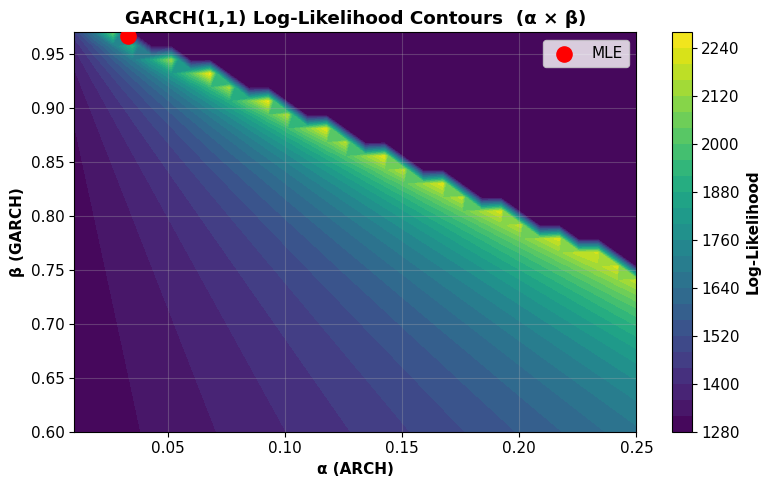

In [15]:

# ── 3D: GARCH likelihood surface over (α, β) ─────────────────────────────────
alpha_range = np.linspace(0.01, 0.25, 30)
beta_range  = np.linspace(0.60, 0.97, 30)
ll_surface  = np.full((len(alpha_range), len(beta_range)), np.nan)

for i, a in enumerate(alpha_range):
    for j, b in enumerate(beta_range):
        if a + b < 1.0:
            om = long_run_var * (1 - a - b)
            s2 = garch_variance_path(log_rets, om, a, b)
            if np.all(s2 > 0):
                ll_surface[i, j] = -0.5 * np.sum(np.log(2*np.pi*s2) + log_rets**2 / s2)

A_grid, B_grid = np.meshgrid(alpha_range, beta_range, indexing='ij')
ll_plot = np.where(~np.isnan(ll_surface), ll_surface, np.nanmin(ll_surface))

# 2D contour companion
fig2d, ax2d = plt.subplots(figsize=(8, 5))
cs = ax2d.contourf(A_grid, B_grid, ll_plot, levels=25, cmap='viridis')
plt.colorbar(cs, ax=ax2d, label='Log-Likelihood')
ax2d.scatter([alpha_hat], [beta_hat], color='red', s=120, zorder=5, label='MLE')
ax2d.set_xlabel('α (ARCH)'); ax2d.set_ylabel('β (GARCH)')
ax2d.set_title('GARCH(1,1) Log-Likelihood Contours  (α × β)'); ax2d.legend()
plt.tight_layout(); plt.show()

# 3D Plotly surface
mle_ll = -0.5 * np.sum(
    np.log(2*np.pi * garch_variance_path(log_rets, omega_hat, alpha_hat, beta_hat)) +
    log_rets**2 / garch_variance_path(log_rets, omega_hat, alpha_hat, beta_hat)
)

fig3d = go.Figure()
fig3d.add_trace(go.Surface(
    x=A_grid, y=B_grid, z=ll_plot,
    colorscale='viridis',
    colorbar=dict(title='Log-Likelihood'),
    opacity=0.88,
    hovertemplate='α=%{x:.3f}<br>β=%{y:.3f}<br>LL=%{z:.1f}<extra></extra>',
))
fig3d.add_trace(go.Scatter3d(
    x=[alpha_hat], y=[beta_hat], z=[mle_ll],
    mode='markers',
    marker=dict(size=8, color='red', symbol='diamond'),
    name='MLE optimum',
    hovertemplate=f'α={alpha_hat:.3f}<br>β={beta_hat:.3f}<br>LL={mle_ll:.1f}<extra>MLE</extra>',
))
fig3d.update_layout(
    title='3D: GARCH(1,1) Log-Likelihood Surface  (fixing long-run variance)',
    scene=dict(
        xaxis_title='α (ARCH term)',
        yaxis_title='β (GARCH term)',
        zaxis_title='Log-Likelihood',
        camera=dict(eye=dict(x=1.6, y=-1.6, z=1.0)),
    ),
    legend=dict(x=0.02, y=0.95),
    height=650, width=1050, margin=dict(l=0, r=0, t=60, b=0),
)
fig3d.show()


---

# Part VII — Volatility Forecasting Comparison

## How to Evaluate a Volatility Forecast?

True instantaneous volatility is **latent** (unobservable). We use **proxy measures** as evaluation targets:
- **Squared returns** $r_t^2$: unbiased but very noisy (high variance)
- **Realized variance** (from intraday data): lower noise, closer to true variance
- **Mincer-Zarnowitz regression**: regress the proxy on the forecast, test $\alpha=0, \beta=1$

## Loss Functions for Volatility

Two standard loss functions for variance forecasts $\hat{\sigma}_t^2$ evaluated against proxy $\sigma_{t}^{2,\text{proxy}}$:

**MSE (Mean Squared Error)**:
$$\text{MSE} = \frac{1}{T}\sum_t (\hat{\sigma}_t^2 - \sigma_t^{2,\text{proxy}})^2$$

**QLIKE (Quasi-Likelihood)**:
$$\text{QLIKE} = \frac{1}{T}\sum_t \left[\frac{\sigma_t^{2,\text{proxy}}}{\hat{\sigma}_t^2} - \ln\frac{\sigma_t^{2,\text{proxy}}}{\hat{\sigma}_t^2} - 1\right]$$

QLIKE is preferred in practice — it penalises underestimation more than overestimation, matching the asymmetric cost of underestimating risk.

Forecast           RMSE (vol%,ann)      MSE (var)      QLIKE
--------------------------------------------------------------
HV-5                       15.3820       3.65e-07   1.113971
HV-21                       6.9258       7.05e-08   0.071563
EWMA-94                     5.6780       4.54e-08   0.054602
GARCH                       5.1346       3.64e-08   0.031585


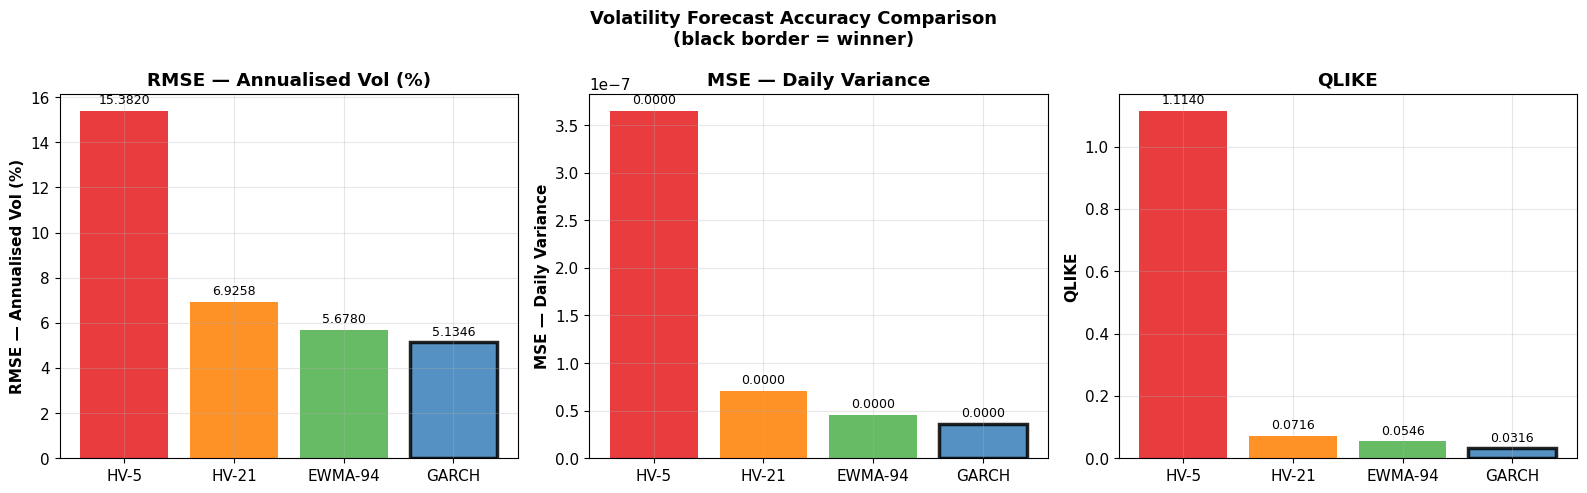

In [16]:

# ── Use true variance as the proxy (we have it in simulation) ────────────────
true_var = vol_path**2   # daily variance

# 1-step-ahead forecasts (shifted by 1 so forecast is made before the day)
def one_step_ahead_garch(rets, omega, alpha, beta):
    """One-step-ahead GARCH forecast — the variance predicted BEFORE observing r_t."""
    sigma2 = garch_variance_path(rets, omega, alpha, beta)
    return np.roll(sigma2, 1)   # shift: sigma2[t] was forecast using info at t-1

forecasts = {
    'HV-5':    hist_vol(log_rets, 5)**2 / 252,
    'HV-21':   hist_vol(log_rets, 21)**2 / 252,
    'EWMA-94': ewma_vol(log_rets, 0.94)**2 / 252,
    'GARCH':   one_step_ahead_garch(log_rets, omega_hat, alpha_hat, beta_hat),
}

def mse(forecast, true):
    valid = ~np.isnan(forecast)
    return np.mean((forecast[valid] - true[valid])**2)

def qlike(forecast, true):
    valid = ~np.isnan(forecast) & (forecast > 0) & (true > 0)
    ratio = true[valid] / forecast[valid]
    return np.mean(ratio - np.log(ratio) - 1)

def rmse_vol(forecast, true):
    """RMSE in annualised vol space."""
    valid = ~np.isnan(forecast) & (forecast > 0)
    return np.sqrt(np.mean((np.sqrt(forecast[valid])*ANN - np.sqrt(true[valid])*ANN)**2)) * 100

print(f'{"Forecast":<15} {"RMSE (vol%,ann)":>18} {"MSE (var)":>14} {"QLIKE":>10}')
print('-' * 62)
scores = {}
for name, fc in forecasts.items():
    r = rmse_vol(fc, true_var)
    m = mse(fc, true_var)
    q = qlike(fc, true_var)
    scores[name] = (r, m, q)
    print(f'{name:<15} {r:>18.4f} {m:>14.2e} {q:>10.6f}')

# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
names = list(scores.keys())
col   = ['#e41a1c','#ff7f00','#4daf4a','#377eb8']

for ax, metric, title in zip(
    axes,
    [0, 1, 2],
    ['RMSE — Annualised Vol (%)', 'MSE — Daily Variance', 'QLIKE']
):
    vals = [scores[n][metric] for n in names]
    bars = ax.bar(names, vals, color=col, alpha=0.85)
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
    ax.set_title(title)
    ax.set_ylabel(title)
    # Highlight the winner by accessing the bar patch directly from the bars container
    best_idx = int(np.argmin(vals))
    bars[best_idx].set_edgecolor('black')
    bars[best_idx].set_linewidth(2.5)

plt.suptitle('Volatility Forecast Accuracy Comparison\n(black border = winner)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---

# Part VIII — Stylized Facts of Volatility

**Stylized facts** are empirical regularities observed across many assets, markets, and time periods — robust enough to be considered properties that any good volatility model must reproduce.

## The Six Key Stylized Facts

| # | Stylized Fact | Description |
|---|--------------|-------------|
| 1 | **Volatility Clustering** | Large moves tend to follow large moves (of either sign) |
| 2 | **Fat Tails** | Return distributions have much heavier tails than Normal |
| 3 | **Leverage Effect** | Negative returns increase future volatility more than positive returns |
| 4 | **Long Memory** | Volatility autocorrelation decays slowly (hyperbolic, not exponential) |
| 5 | **Vol Mean Reversion** | Volatility eventually reverts to a long-run average |
| 6 | **Vol Skew** | The distribution of vol changes is right-skewed (spikes up faster than it calms) |

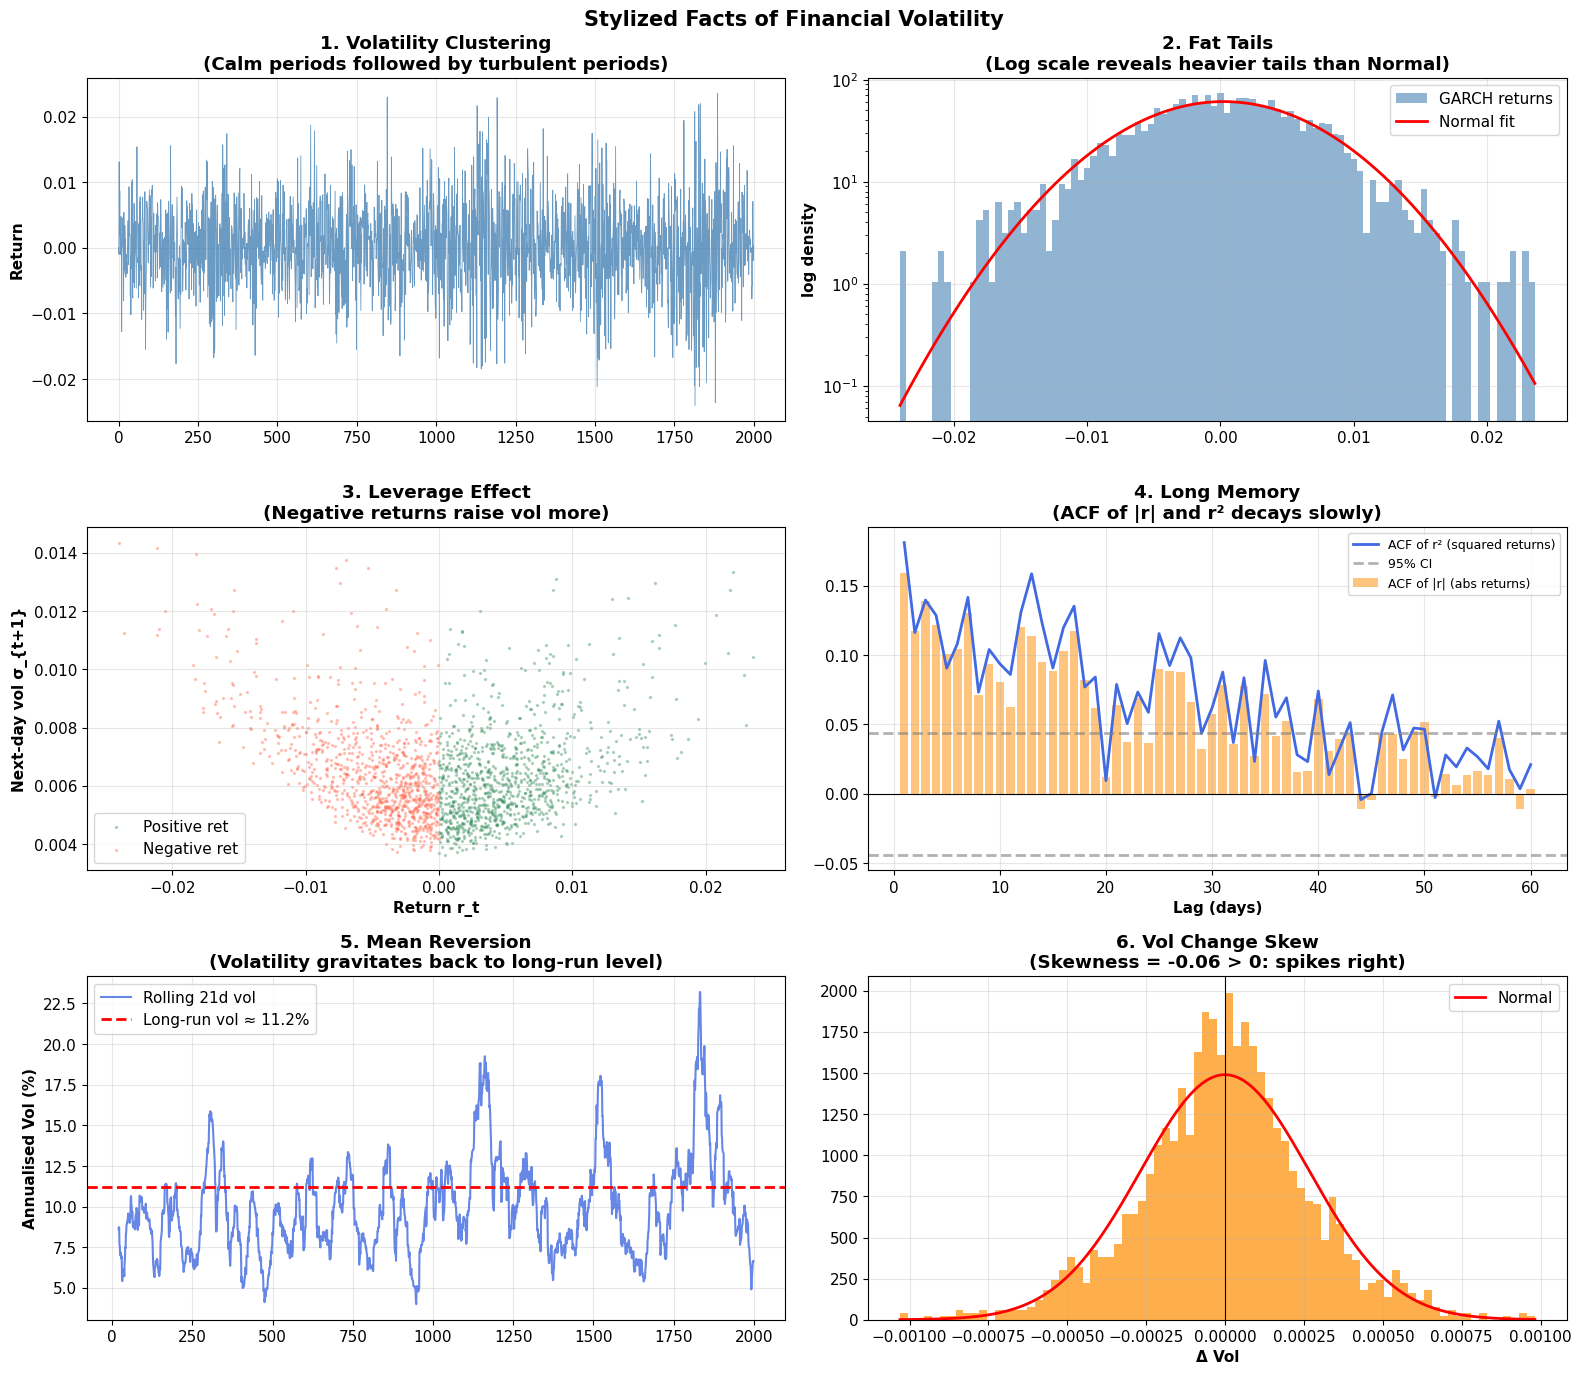

Excess kurtosis of returns: 0.58  (Normal = 0)
Skewness of vol changes:    -0.061  (Normal = 0)


In [17]:
# ── Simulate GARCH returns for stylized fact demonstration ────────────────────
# Use a GARCH(1,1) with leverage effect (GJR-GARCH / Threshold GARCH)
np.random.seed(99)
n_sf = 2000

omega_sf = 1e-6
alpha_sf = 0.06
gamma_sf = 0.08   # leverage: extra sensitivity for negative returns
beta_sf  = 0.88

r_sf   = np.zeros(n_sf)
sig_sf = np.zeros(n_sf)
sig_sf[0] = np.sqrt(omega_sf / (1 - alpha_sf - beta_sf - gamma_sf * 0.5))

for i in range(1, n_sf):
    indicator  = 1.0 if r_sf[i-1] < 0 else 0.0   # leverage indicator
    sig2_prev  = sig_sf[i-1]**2
    sig2_i = omega_sf + (alpha_sf + gamma_sf * indicator) * r_sf[i-1]**2 + beta_sf * sig2_prev
    sig_sf[i] = np.sqrt(max(sig2_i, 1e-10))
    r_sf[i]   = sig_sf[i] * np.random.standard_normal()

abs_r = np.abs(r_sf)

# ── 6-panel figure for all stylized facts ─────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(16, 14))

t_sf = np.arange(n_sf)

# 1. Volatility Clustering
ax = axes[0, 0]
ax.plot(t_sf, r_sf, color='steelblue', linewidth=0.6, alpha=0.8)
ax.set_title('1. Volatility Clustering\n(Calm periods followed by turbulent periods)')
ax.set_ylabel('Return')

# 2. Fat Tails — compare to normal
ax = axes[0, 1]
mu_sf, std_sf = r_sf.mean(), r_sf.std()
xr = np.linspace(r_sf.min(), r_sf.max(), 400)
ax.hist(r_sf, bins=100, density=True, color='steelblue', alpha=0.6, label='GARCH returns')
ax.plot(xr, stats.norm.pdf(xr, mu_sf, std_sf), 'r-', linewidth=2, label='Normal fit')
ax.set_yscale('log')
ax.set_title('2. Fat Tails\n(Log scale reveals heavier tails than Normal)')
ax.legend()
ax.set_ylabel('log density')

# 3. Leverage Effect
ax = axes[1, 0]
neg_mask = r_sf[:-1] < 0
pos_mask = r_sf[:-1] >= 0
ax.scatter(r_sf[:-1][pos_mask], sig_sf[1:][pos_mask], s=2, alpha=0.3, color='seagreen', label='Positive ret')
ax.scatter(r_sf[:-1][neg_mask], sig_sf[1:][neg_mask], s=2, alpha=0.3, color='tomato', label='Negative ret')
ax.set_xlabel('Return r_t')
ax.set_ylabel('Next-day vol σ_{t+1}')
ax.set_title('3. Leverage Effect\n(Negative returns raise vol more)')
ax.legend()

# 4. Long Memory — ACF of |r| and r²
ax = axes[1, 1]
max_lag = 60
acf_r2   = [pd.Series(r_sf**2).autocorr(lag=k) for k in range(1, max_lag + 1)]
acf_absr = [pd.Series(abs_r).autocorr(lag=k) for k in range(1, max_lag + 1)]
lags = np.arange(1, max_lag + 1)
ax.bar(lags, acf_absr, alpha=0.5, color='darkorange', label='ACF of |r| (abs returns)')
ax.plot(lags, acf_r2, 'royalblue', linewidth=2, label='ACF of r² (squared returns)')
ax.axhline(0, color='k', linewidth=0.8)
ax.axhline(1.96/np.sqrt(n_sf), color='gray', linestyle='--', alpha=0.6, label='95% CI')
ax.axhline(-1.96/np.sqrt(n_sf), color='gray', linestyle='--', alpha=0.6)
ax.set_title('4. Long Memory\n(ACF of |r| and r² decays slowly)')
ax.set_xlabel('Lag (days)')
ax.legend(fontsize=9)

# 5. Mean Reversion — rolling vol over time
ax = axes[2, 0]
rv_rolling = pd.Series(r_sf**2).rolling(21).mean().values
rv_rolling = np.sqrt(rv_rolling) * ANN * 100
lr_level   = np.sqrt(omega_sf / (1 - alpha_sf - beta_sf - gamma_sf*0.5)) * ANN * 100
ax.plot(t_sf, rv_rolling, color='royalblue', linewidth=1.5, alpha=0.8, label='Rolling 21d vol')
ax.axhline(lr_level, color='red', linestyle='--', linewidth=2,
           label=f'Long-run vol ≈ {lr_level:.1f}%')
ax.set_title('5. Mean Reversion\n(Volatility gravitates back to long-run level)')
ax.set_ylabel('Annualised Vol (%)')
ax.legend()

# 6. Right Skew of Vol Changes
ax = axes[2, 1]
rv21 = pd.Series(abs_r).rolling(21).mean().values
vol_changes = np.diff(rv21[~np.isnan(rv21)])
ax.hist(vol_changes, bins=80, density=True, color='darkorange', alpha=0.7)
x_vc = np.linspace(vol_changes.min(), vol_changes.max(), 300)
ax.plot(x_vc, stats.norm.pdf(x_vc, vol_changes.mean(), vol_changes.std()),
        'r-', linewidth=2, label='Normal')
ax.axvline(0, color='k', linewidth=0.8)
sk_vc = stats.skew(vol_changes)
ax.set_title(f'6. Vol Change Skew\n(Skewness = {sk_vc:.2f} > 0: spikes right)')
ax.legend()
ax.set_xlabel('Δ Vol')

plt.suptitle('Stylized Facts of Financial Volatility', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Excess kurtosis of returns: {stats.kurtosis(r_sf):.2f}  (Normal = 0)')
print(f'Skewness of vol changes:    {stats.skew(vol_changes):.3f}  (Normal = 0)')

---

# Part IX — Volatility of Volatility (VoV)

## 9.1 What is VoV?

**Volatility of Volatility** measures how much the volatility estimate itself varies over time. It is a second-order risk measure.

**Why it matters:**
- Options on VIX trade VoV directly (VIX options, VVIX index)
- High VoV means your vol estimate is uncertain — you need wider confidence intervals on risk measures
- VoV is positively correlated with tail risk: when VoV is high, large unexpected vol spikes are more likely
- Position sizing based on vol targeting becomes less reliable under high VoV

## 9.2 Computing VoV

We apply a rolling standard deviation to the volatility estimate itself:

$$\text{VoV}_t = \text{std}_{w_2}\!\left(\hat{\sigma}_{t-w_2+1}, \ldots, \hat{\sigma}_t\right)$$

## 9.3 VVIX — The VIX of VIX

The CBOE publishes the **VVIX index** — the implied volatility of VIX options, which is directly the market's expectation of VoV. Typical VVIX levels:
- ~70–90: normal
- >100: elevated uncertainty
- >120: extreme regime (March 2020, GFC)

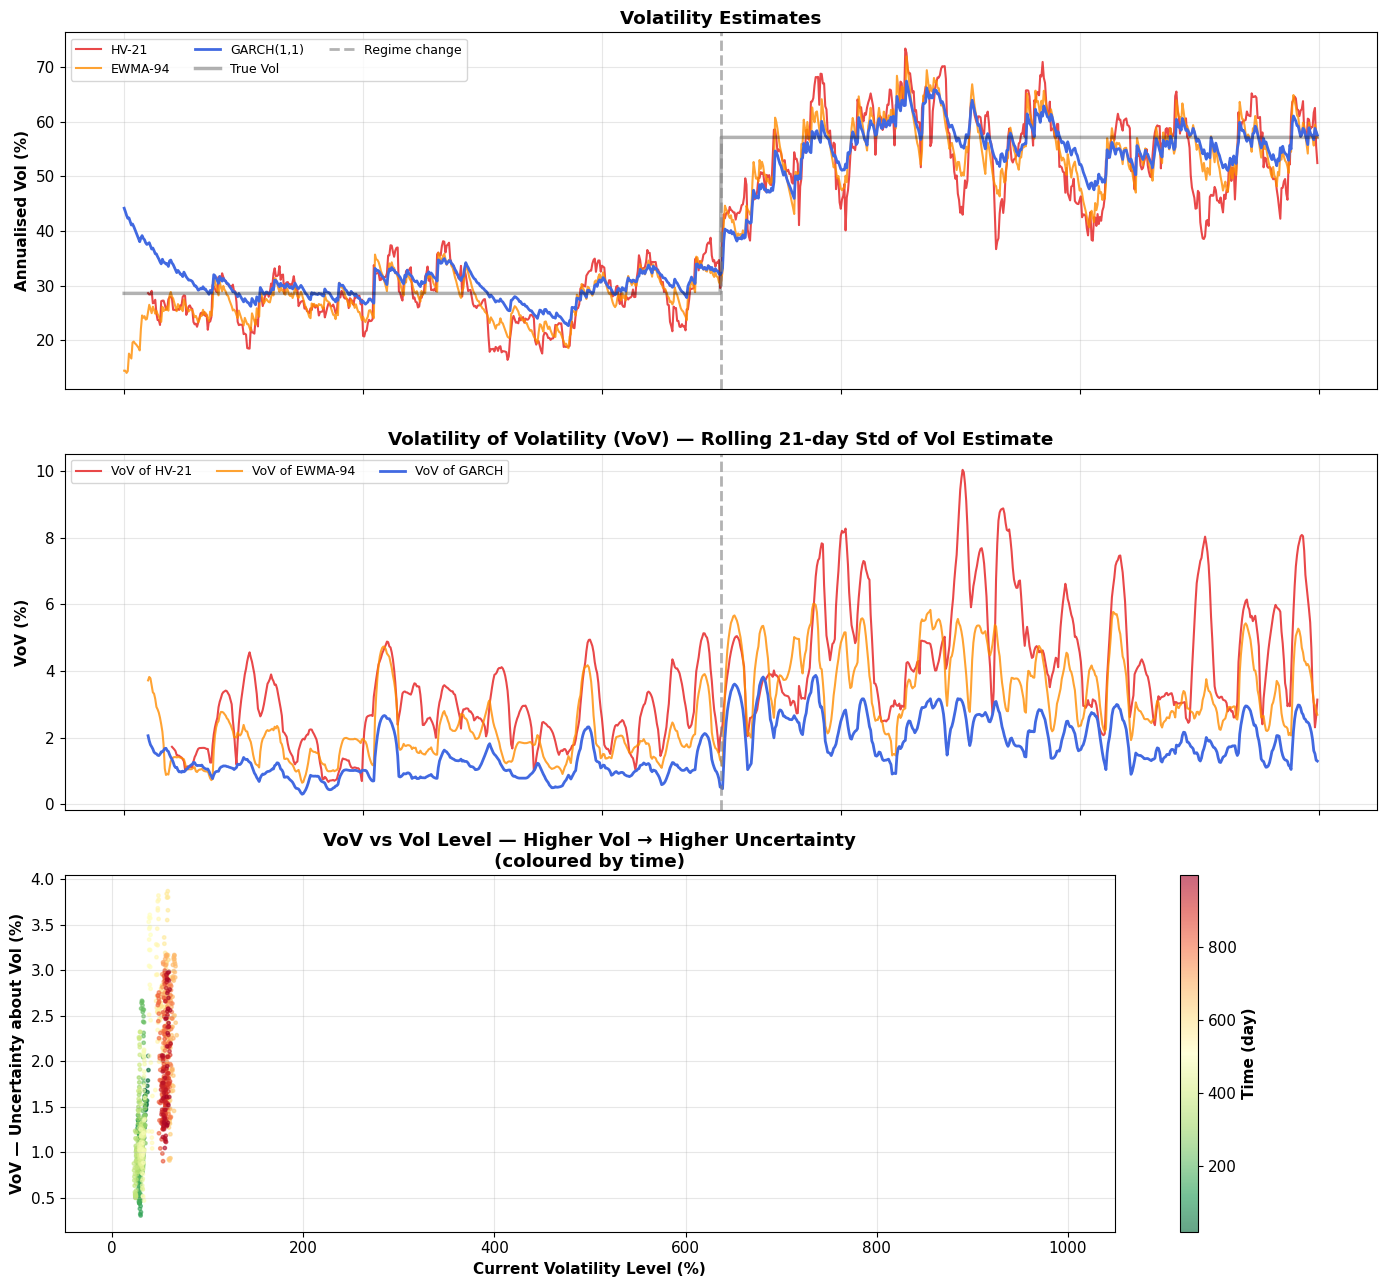

Correlation (GARCH vol, VoV) = 0.658


In [18]:
# ── Compute VoV from each estimator ───────────────────────────────────────────
vov_window = 21   # 1-month rolling std of vol

hv21  = hist_vol(log_rets, 21) * 100
ew94  = ewma_vol(log_rets, 0.94) * 100
g11   = sigma_garch

vov_hv   = pd.Series(hv21).rolling(vov_window).std().values
vov_ew   = pd.Series(ew94).rolling(vov_window).std().values
vov_garch = pd.Series(g11).rolling(vov_window).std().values

fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)

# Vol time series
ax = axes[0]
ax.plot(t, hv21,  color='#e41a1c', linewidth=1.5, alpha=0.8, label='HV-21')
ax.plot(t, ew94,  color='darkorange', linewidth=1.5, alpha=0.8, label='EWMA-94')
ax.plot(t, g11,   color='royalblue', linewidth=2, label='GARCH(1,1)')
ax.plot(t, true_ann, 'k-', linewidth=2.5, alpha=0.3, label='True Vol')
ax.axvline(500, color='gray', linestyle='--', alpha=0.6, label='Regime change')
ax.set_title('Volatility Estimates')
ax.set_ylabel('Annualised Vol (%)')
ax.legend(ncol=3, fontsize=9)

# VoV time series
ax2 = axes[1]
ax2.plot(t, vov_hv,    color='#e41a1c', linewidth=1.5, alpha=0.8, label='VoV of HV-21')
ax2.plot(t, vov_ew,    color='darkorange', linewidth=1.5, alpha=0.8, label='VoV of EWMA-94')
ax2.plot(t, vov_garch, color='royalblue', linewidth=2, label='VoV of GARCH')
ax2.axvline(500, color='gray', linestyle='--', alpha=0.6)
ax2.set_title('Volatility of Volatility (VoV) — Rolling 21-day Std of Vol Estimate')
ax2.set_ylabel('VoV (%)')
ax2.legend(ncol=3, fontsize=9)

# VoV vs Vol scatter (GARCH)
ax3 = axes[2]
valid_vov = ~np.isnan(vov_garch)
sc = ax3.scatter(g11[valid_vov], vov_garch[valid_vov],
                 c=t[valid_vov], cmap='RdYlGn_r', s=6, alpha=0.6)
plt.colorbar(sc, ax=ax3, label='Time (day)')
ax3.set_xlabel('Current Volatility Level (%)')
ax3.set_ylabel('VoV — Uncertainty about Vol (%)')
ax3.set_title('VoV vs Vol Level — Higher Vol → Higher Uncertainty\n(coloured by time)')

plt.tight_layout()
plt.show()

# Correlation between vol and VoV
valid = ~np.isnan(vov_garch)
corr_vov = np.corrcoef(g11[valid], vov_garch[valid])[0, 1]
print(f'Correlation (GARCH vol, VoV) = {corr_vov:.3f}')

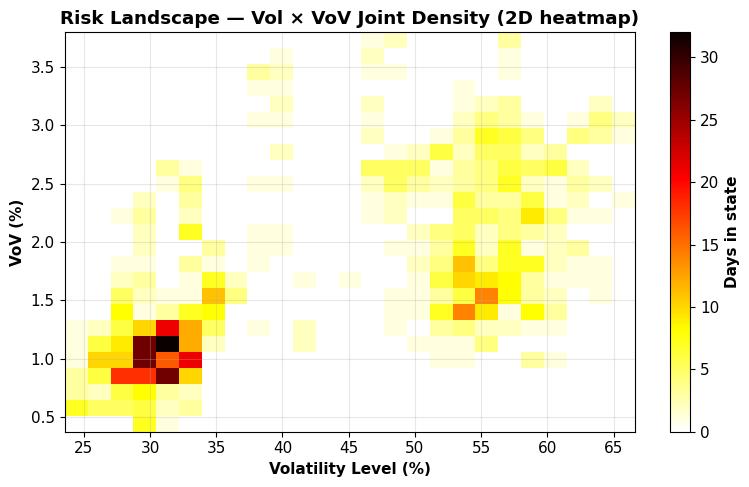

In [19]:

# ── 3D: Vol surface over (vol level, VoV) — risk landscape ───────────────────
valid  = ~np.isnan(vov_garch) & ~np.isnan(hv21)
vol_v  = g11[valid]
vov_v  = vov_garch[valid]

# Bin into a grid to smooth
n_bins = 25
vol_bins = np.linspace(vol_v.min(), vol_v.max(), n_bins + 1)
vov_bins = np.linspace(vov_v.min(), vov_v.max(), n_bins + 1)

density = np.zeros((n_bins, n_bins))
for i in range(n_bins):
    for j in range(n_bins):
        mask = ((vol_v >= vol_bins[i]) & (vol_v < vol_bins[i+1]) &
                (vov_v >= vov_bins[j]) & (vov_v < vov_bins[j+1]))
        density[i, j] = mask.sum()

vol_centers = (vol_bins[:-1] + vol_bins[1:]) / 2
vov_centers = (vov_bins[:-1] + vov_bins[1:]) / 2
VC, VVC = np.meshgrid(vol_centers, vov_centers, indexing='ij')

# 2D companion: density heatmap
fig2d, ax2d = plt.subplots(figsize=(8, 5))
im2d = ax2d.imshow(density.T, origin='lower', aspect='auto', cmap='hot_r',
                   extent=[vol_centers[0], vol_centers[-1], vov_centers[0], vov_centers[-1]])
plt.colorbar(im2d, ax=ax2d, label='Days in state')
ax2d.set_xlabel('Volatility Level (%)'); ax2d.set_ylabel('VoV (%)')
ax2d.set_title('Risk Landscape — Vol × VoV Joint Density (2D heatmap)')
plt.tight_layout(); plt.show()

# 3D Plotly surface
fig3d = go.Figure(go.Surface(
    x=VC, y=VVC, z=density,
    colorscale='hot_r',
    reversescale=True,
    colorbar=dict(title='Days in State'),
    hovertemplate='Vol=%{x:.1f}%<br>VoV=%{y:.1f}%<br>Days=%{z:.0f}<extra></extra>',
))
fig3d.update_layout(
    title='3D: Risk Landscape — Vol × VoV Joint Distribution<br>(How often each (vol, VoV) state occurs)',
    scene=dict(
        xaxis_title='Volatility Level (%)',
        yaxis_title='VoV (%)',
        zaxis_title='Time Spent in State (days)',
        camera=dict(eye=dict(x=1.6, y=-1.6, z=1.0)),
    ),
    height=650, width=1050, margin=dict(l=0, r=0, t=80, b=0),
)
fig3d.show()


---

# Part X — Volatility Regime Detection

## 10.1 Two-Regime Volatility Model

Markets switch between **calm** (low-vol) and **turbulent** (high-vol) regimes. Detecting the current regime is valuable for:
- Dynamic position sizing
- Risk-on / risk-off asset allocation
- Conditional strategy selection

## 10.2 Threshold-Based Regime Classification

The simplest approach: compare current vol to a threshold (e.g., the long-run median).

## 10.3 Hidden Markov Model (HMM) for Regimes

A more principled approach: assume returns come from a mixture of two Gaussian distributions with different variances. The model learns the transition probabilities between regimes.

$$P(r_t | S_t = k) = \mathcal{N}(\mu_k, \sigma_k^2)$$
$$P(S_t = j | S_{t-1} = i) = A_{ij}$$

The **Baum-Welch algorithm** (EM for HMMs) estimates all parameters from data. The **Viterbi algorithm** decodes the most likely regime sequence.

In [20]:
from scipy.special import logsumexp

# ══════════════════════════════════════════════════════════════════════════════
# Simple 2-state HMM for volatility regimes (Gaussian emissions)
# ══════════════════════════════════════════════════════════════════════════════

class GaussianHMM2State:
    """2-state HMM with Gaussian emissions. Fit via Baum-Welch (EM)."""

    def __init__(self, mu0=None, sigma0=None):
        # Transition matrix rows = from-state, cols = to-state
        self.A  = np.array([[0.98, 0.02],
                             [0.05, 0.95]])
        # Emission parameters (low-vol, high-vol)
        self.mu    = np.array([0.0, 0.0])
        self.sigma = np.array([0.01, 0.03]) if sigma0 is None else np.array(sigma0)
        self.pi    = np.array([0.7, 0.3])   # initial state distribution

    def _emission_log_prob(self, obs):
        """Log emission probabilities: (T, K)."""
        T, K = len(obs), 2
        log_b = np.zeros((T, K))
        for k in range(K):
            log_b[:, k] = stats.norm.logpdf(obs, self.mu[k], self.sigma[k])
        return log_b

    def _forward(self, log_b):
        T = log_b.shape[0]
        log_alpha = np.zeros((T, 2))
        log_alpha[0] = np.log(self.pi + 1e-300) + log_b[0]
        for t in range(1, T):
            for j in range(2):
                log_alpha[t, j] = logsumexp(log_alpha[t-1] + np.log(self.A[:, j] + 1e-300)) + log_b[t, j]
        return log_alpha

    def _backward(self, log_b):
        T = log_b.shape[0]
        log_beta = np.zeros((T, 2))
        for t in range(T - 2, -1, -1):
            for i in range(2):
                log_beta[t, i] = logsumexp(np.log(self.A[i, :] + 1e-300) + log_b[t+1] + log_beta[t+1])
        return log_beta

    def fit(self, obs, n_iter=50):
        for _ in range(n_iter):
            log_b     = self._emission_log_prob(obs)
            log_alpha = self._forward(log_b)
            log_beta  = self._backward(log_b)

            # Posterior state probabilities γ (T, K)
            log_gamma = log_alpha + log_beta
            log_gamma -= logsumexp(log_gamma, axis=1, keepdims=True)
            gamma = np.exp(log_gamma)

            # Xi (T-1, K, K)
            T = len(obs)
            log_xi = np.zeros((T-1, 2, 2))
            for t in range(T - 1):
                for i in range(2):
                    for j in range(2):
                        log_xi[t, i, j] = (log_alpha[t, i]
                                           + np.log(self.A[i, j] + 1e-300)
                                           + log_b[t+1, j]
                                           + log_beta[t+1, j])
                log_xi[t] -= logsumexp(log_xi[t].ravel())

            xi = np.exp(log_xi)

            # M-step
            self.pi = gamma[0] / gamma[0].sum()
            self.A  = xi.sum(0) / xi.sum(0).sum(1, keepdims=True)
            for k in range(2):
                self.mu[k]    = (gamma[:, k] * obs).sum() / gamma[:, k].sum()
                self.sigma[k] = np.sqrt((gamma[:, k] * (obs - self.mu[k])**2).sum()
                                         / gamma[:, k].sum())
        self.gamma_ = gamma

    def viterbi(self, obs):
        """Decode most likely state sequence."""
        T, log_b = len(obs), self._emission_log_prob(obs)
        delta = np.zeros((T, 2))
        psi   = np.zeros((T, 2), dtype=int)
        delta[0] = np.log(self.pi + 1e-300) + log_b[0]
        for t in range(1, T):
            for j in range(2):
                scores    = delta[t-1] + np.log(self.A[:, j] + 1e-300)
                psi[t, j] = np.argmax(scores)
                delta[t, j] = scores[psi[t, j]] + log_b[t, j]
        states = np.zeros(T, dtype=int)
        states[-1] = np.argmax(delta[-1])
        for t in range(T-2, -1, -1):
            states[t] = psi[t+1, states[t+1]]
        return states

hmm = GaussianHMM2State()
hmm.fit(log_rets, n_iter=80)
decoded = hmm.viterbi(log_rets)

# Ensure state 0 = low vol, state 1 = high vol
if hmm.sigma[0] > hmm.sigma[1]:
    decoded = 1 - decoded
    hmm.sigma = hmm.sigma[::-1]
    hmm.mu    = hmm.mu[::-1]

prob_high_vol = hmm.gamma_[:, 1] if hmm.sigma[1] > hmm.sigma[0] else hmm.gamma_[:, 0]

print('HMM fitted parameters:')
print(f'  State 0 (Low Vol):  μ={hmm.mu[0]:.5f}, σ={hmm.sigma[0]:.5f} ({hmm.sigma[0]*ANN:.1%} ann.)')
print(f'  State 1 (High Vol): μ={hmm.mu[1]:.5f}, σ={hmm.sigma[1]:.5f} ({hmm.sigma[1]*ANN:.1%} ann.)')
print(f'  Transition matrix:\n    {hmm.A}')

HMM fitted parameters:
  State 0 (Low Vol):  μ=0.00031, σ=0.01763 (28.0% ann.)
  State 1 (High Vol): μ=0.00074, σ=0.03508 (55.7% ann.)
  Transition matrix:
    [[9.97985011e-01 2.01498884e-03]
 [2.02322135e-95 1.00000000e+00]]


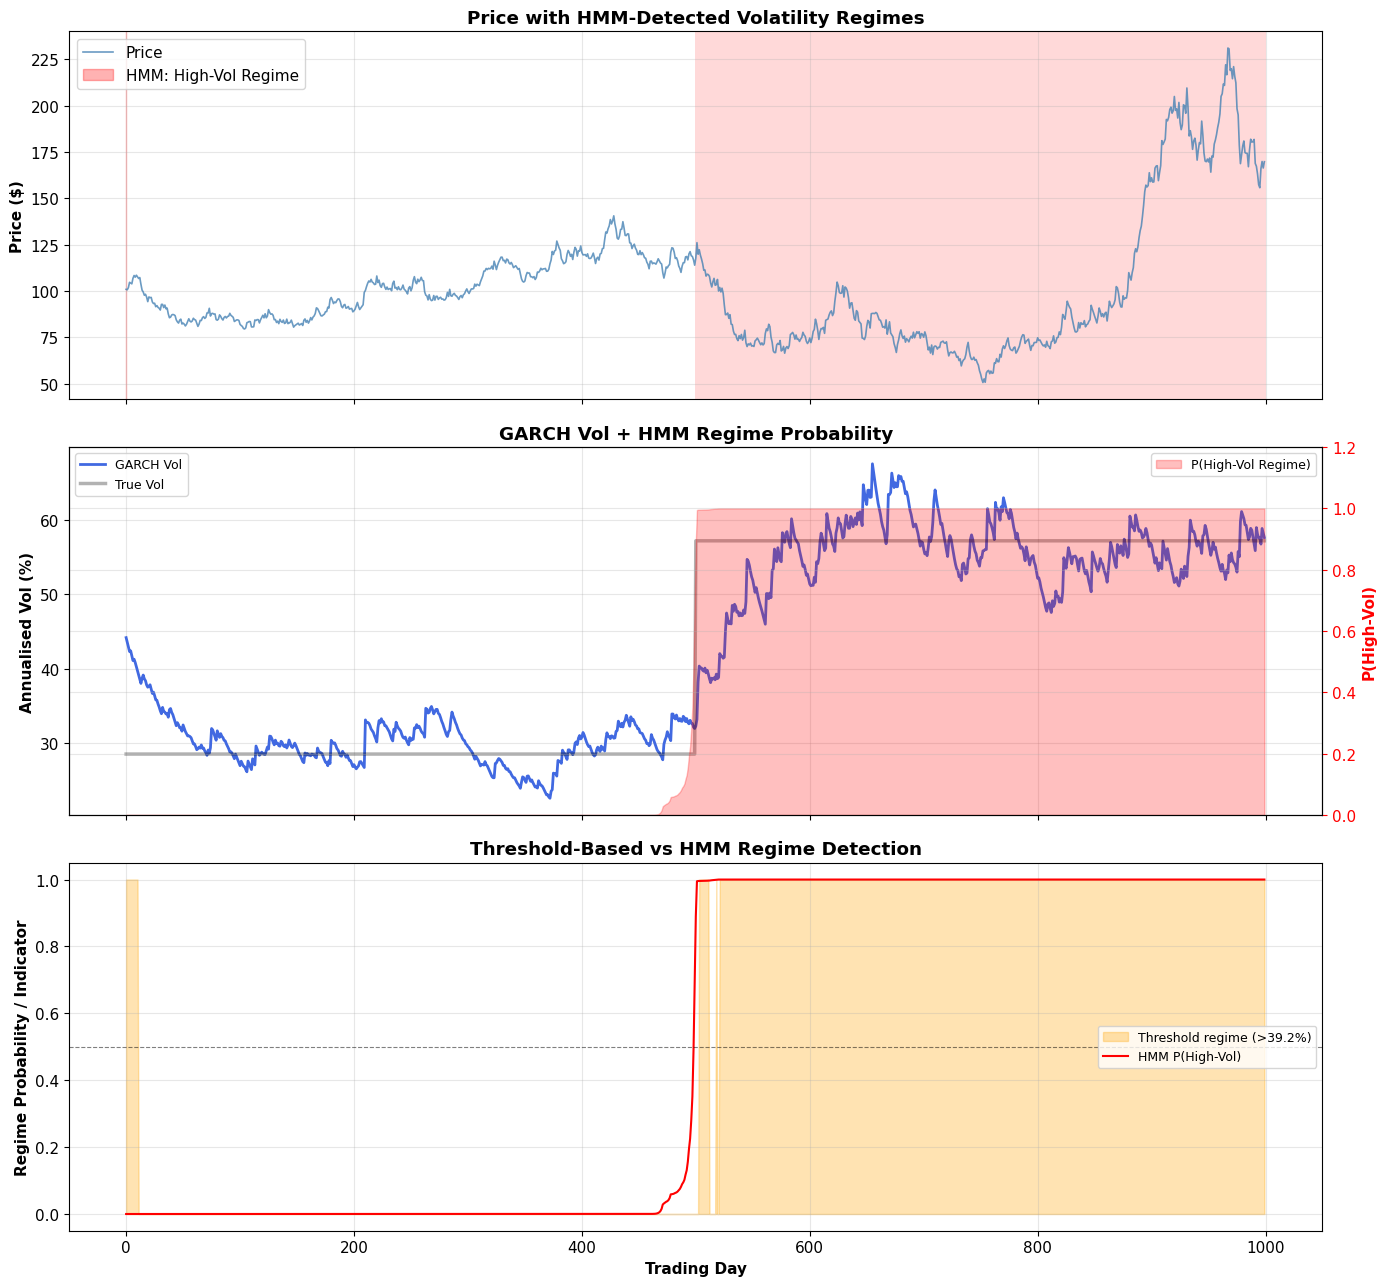

HMM regime detection accuracy vs true regime: 99.9%


In [21]:
# ── Visualise regime detection ────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)

# Price with regime overlay
ax = axes[0]
ax.plot(t, prices[1:], color='steelblue', linewidth=1.2, alpha=0.8, label='Price')
for i in range(len(t)):
    if decoded[i] == 1:
        ax.axvspan(t[i], t[i]+1, alpha=0.15, color='red', linewidth=0)
ax.axvspan(0, 0, alpha=0.3, color='red', label='HMM: High-Vol Regime')
ax.set_title('Price with HMM-Detected Volatility Regimes')
ax.set_ylabel('Price ($)')
ax.legend()

# Vol + regime probability
ax2 = axes[1]
ax2.plot(t, g11, color='royalblue', linewidth=2, label='GARCH Vol')
ax2.plot(t, true_ann, 'k-', linewidth=2.5, alpha=0.3, label='True Vol')
ax2_r = ax2.twinx()
ax2_r.fill_between(t, prob_high_vol, alpha=0.25, color='red',
                   label='P(High-Vol Regime)')
ax2_r.set_ylabel('P(High-Vol)', color='red')
ax2_r.tick_params(axis='y', colors='red')
ax2_r.set_ylim(0, 1.2)
ax2.set_title('GARCH Vol + HMM Regime Probability')
ax2.set_ylabel('Annualised Vol (%)')
ax2.legend(loc='upper left', fontsize=9)
ax2_r.legend(loc='upper right', fontsize=9)

# Threshold-based vs HMM comparison
ax3 = axes[2]
threshold = np.median(g11[~np.isnan(g11)])
threshold_regime = (g11 > threshold).astype(float)
ax3.fill_between(t, threshold_regime, alpha=0.3, color='orange',
                 label=f'Threshold regime (>{threshold:.1f}%)')
ax3.plot(t, prob_high_vol, color='red', linewidth=1.5, label='HMM P(High-Vol)')
ax3.axhline(0.5, color='k', linestyle='--', alpha=0.5, linewidth=0.8)
ax3.set_title(f'Threshold-Based vs HMM Regime Detection')
ax3.set_xlabel('Trading Day')
ax3.set_ylabel('Regime Probability / Indicator')
ax3.legend(fontsize=9)

plt.tight_layout()
plt.show()

accuracy = np.mean(decoded == (vol_path > vol_path[:500].mean() * 1.5).astype(int))
print(f'HMM regime detection accuracy vs true regime: {accuracy:.1%}')

---

# Part XI — Volatility as an ML Feature

## 11.1 Why Volatility Features?

Volatility captures information that raw price features cannot:
- The *uncertainty* of the environment (risk regime)
- The *speed* of price changes (momentum quality)
- The *predictability* of next-period moves (via clustering)

Raw returns are nearly unpredictable (efficient markets). But volatility **is** predictable — GARCH models demonstrate this empirically. This makes volatility features valuable for:

- **Regime classification** (is this a risk-on or risk-off period?)
- **Position sizing** (vol-targeting strategies)
- **Return predictability** (low-vol anomaly, risk premia)
- **Options pricing** (vol forecasts directly price derivatives)

## 11.2 Feature Engineering from Volatility

| Feature | Formula | Captures |
|---------|---------|---------|
| Rolling HV | std(r, w) | Current vol level |
| EWMA vol | EWMA(r², λ) | Recency-weighted vol |
| Vol momentum | HV_5 / HV_21 | Whether vol is spiking or calming |
| Vol percentile | rank(HV_21) | Where vol sits in its history |
| VoV | std(HV_21, w) | Uncertainty about vol |
| Regime prob | P(high-vol | HMM) | Probabilistic regime state |
| GARCH shock | r²/σ² - 1 | Standardised return shock |

Feature matrix shape: (1000, 10)

Feature statistics:
           HV_5     HV_21     HV_63    EWMA_94  GARCH_vol   Vol_Mom   Vol_Pct  \
count  996.0000  980.0000  938.0000  1000.0000  1000.0000  980.0000  729.0000   
mean     0.3959    0.4147    0.4180     0.4105     0.4271    0.9631    0.5859   
std      0.1976    0.1506    0.1396     0.1479     0.1325    0.3063    0.3262   
min      0.0287    0.1639    0.2106     0.1400     0.2265    0.0559    0.0040   
25%      0.2362    0.2782    0.2814     0.2731     0.3001    0.7422    0.2817   
50%      0.3521    0.3903    0.4315     0.3575     0.3922    0.9641    0.6230   
75%      0.5315    0.5557    0.5532     0.5507     0.5573    1.1681    0.9048   
max      1.1493    0.7342    0.6504     0.7199     0.6747    1.7716    1.0000   

            VoV   Regime_P  GARCH_shock  
count  980.0000  1000.0000    1000.0000  
mean     0.0286     0.5037      -0.0167  
std      0.0132     0.4973       1.4908  
min      0.0065     0.0000      -1.0000  
25%   

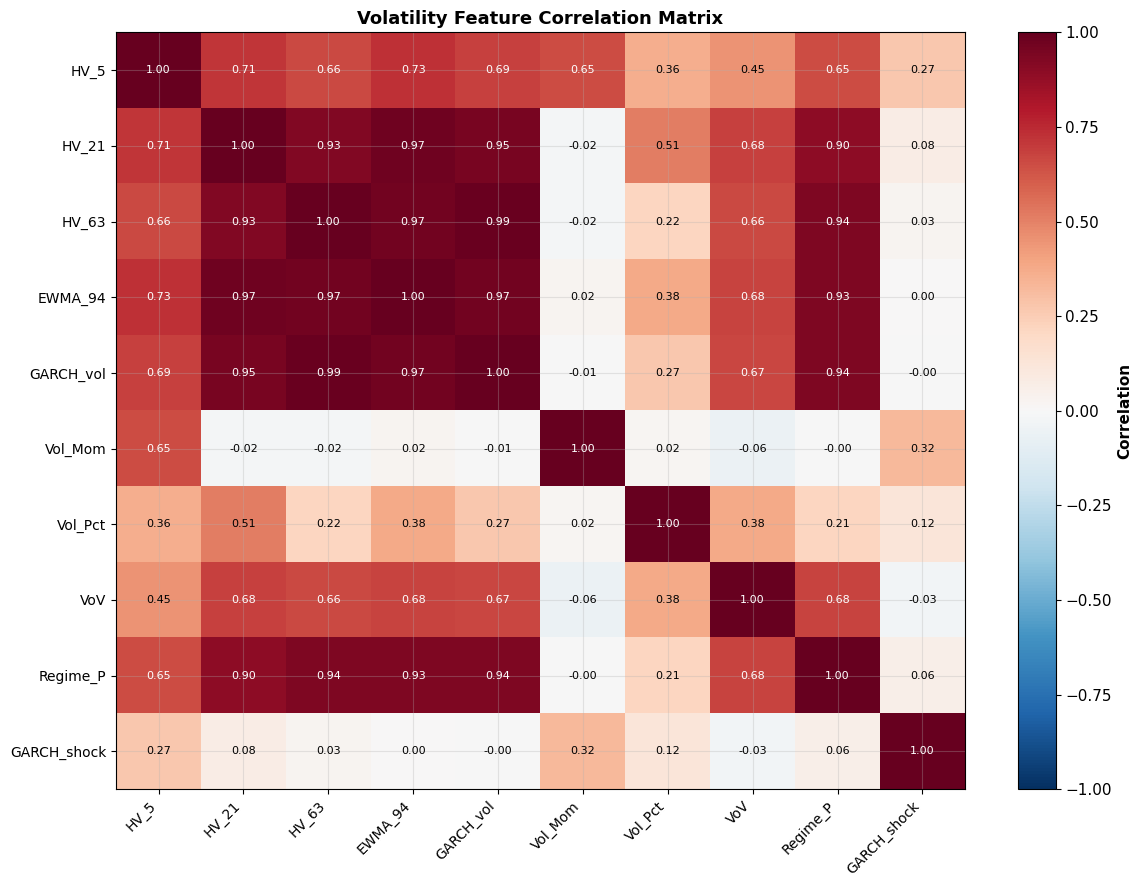

In [22]:
# ── Build a volatility feature matrix ─────────────────────────────────────────
hv5  = hist_vol(log_rets, 5)
hv21 = hist_vol(log_rets, 21)
hv63 = hist_vol(log_rets, 63)
ew94 = ewma_vol(log_rets, 0.94)
g11  = np.sqrt(sigma2_garch) * ANN

# Vol momentum (short/long vol ratio — > 1 means vol is rising)
vol_mom = hv5 / (hv21 + 1e-9)

# Vol percentile (rolling rank)
vol_pct = pd.Series(hv21).rolling(252).rank(pct=True).values

# VoV (21-day std of EWMA vol)
vov_feat = pd.Series(ew94).rolling(21).std().values

# Regime probability from HMM
regime_prob = prob_high_vol

# GARCH standardised shock: r²/σ² - 1
garch_shock = log_rets**2 / (sigma2_garch + 1e-12) - 1

features_df = pd.DataFrame({
    'HV_5':       hv5,
    'HV_21':      hv21,
    'HV_63':      hv63,
    'EWMA_94':    ew94,
    'GARCH_vol':  g11,
    'Vol_Mom':    vol_mom,
    'Vol_Pct':    vol_pct,
    'VoV':        vov_feat,
    'Regime_P':   regime_prob,
    'GARCH_shock': garch_shock,
}, index=t)

print('Feature matrix shape:', features_df.shape)
print('\nFeature statistics:')
print(features_df.describe().round(4))

# ── Feature correlation heatmap ───────────────────────────────────────────────
import matplotlib.colors as mcolors
corr = features_df.corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, label='Correlation')
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(corr.columns, fontsize=10)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(corr.values[i,j]) > 0.6 else 'black')
ax.set_title('Volatility Feature Correlation Matrix', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

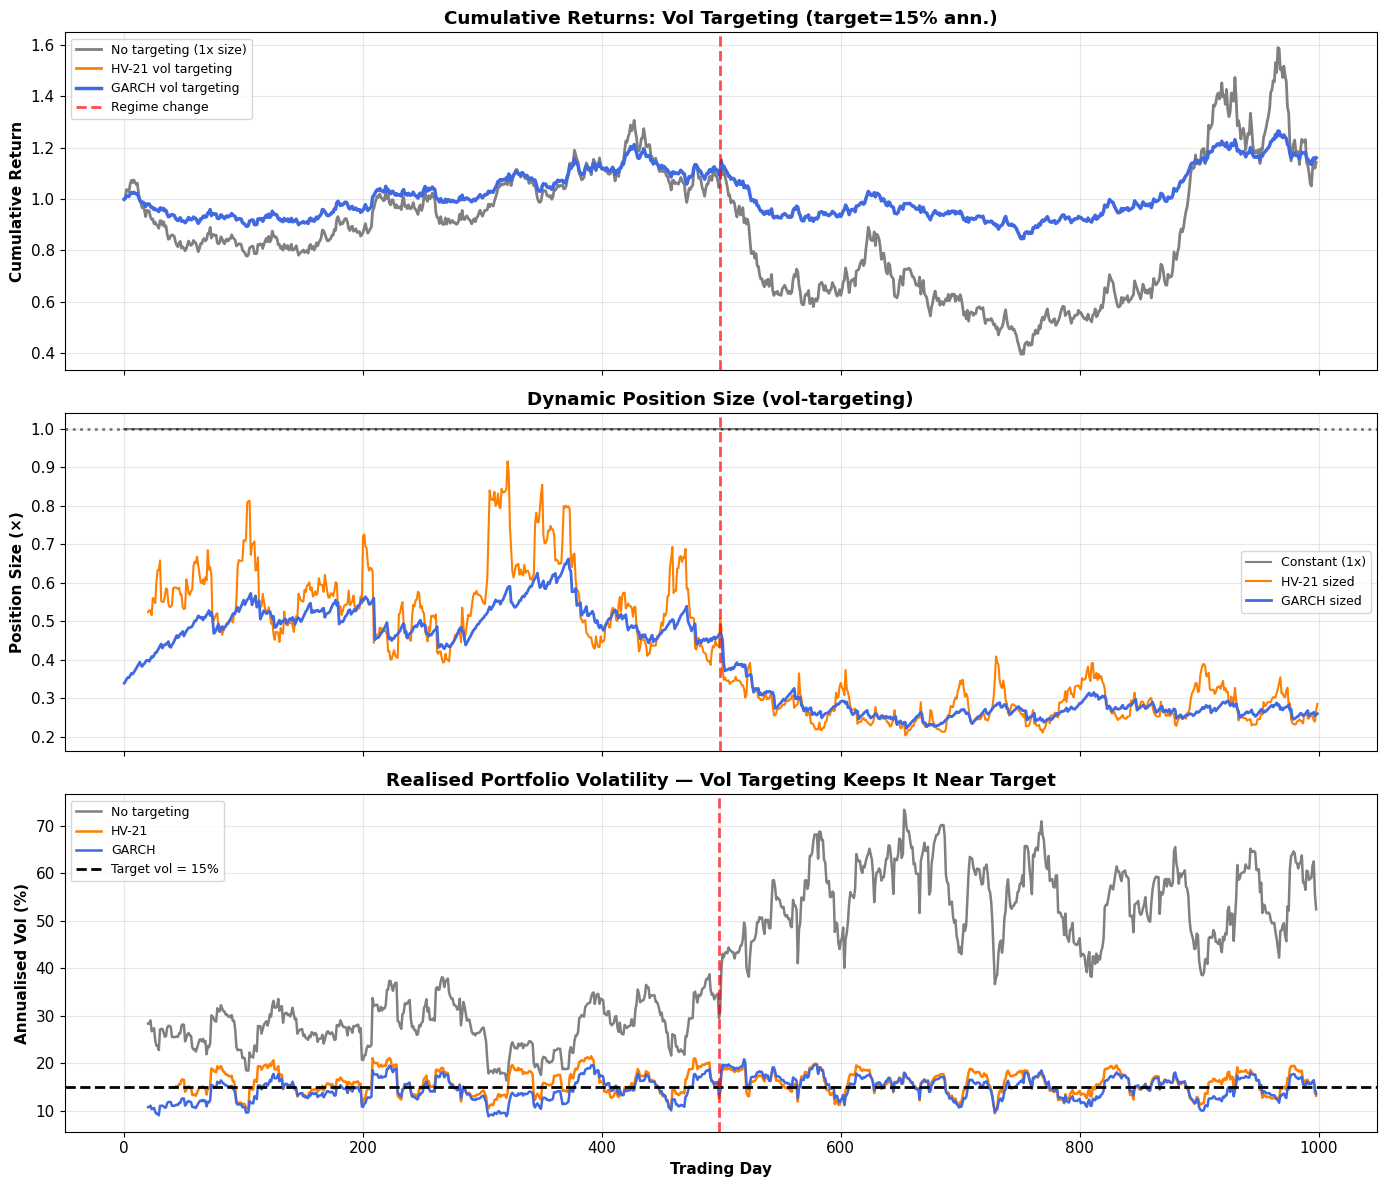

No targeting      : Ann.Vol=44.19%  Sharpe≈0.30
HV-21 target      : Ann.Vol=nan%  Sharpe≈nan
GARCH target      : Ann.Vol=14.89%  Sharpe≈0.33


In [23]:
# ── Vol targeting: dynamic position size using vol estimate ───────────────────
# Vol targeting: size position so expected daily PnL vol = target_vol
# Size_t = target_vol / estimated_vol_t

target_vol_ann = 0.15   # 15% annualised portfolio vol target

def vol_target_size(vol_estimate_ann, target_ann, max_leverage=2.0):
    """Position size = target / current_vol, capped at max_leverage."""
    size = target_ann / (vol_estimate_ann + 1e-9)
    return np.clip(size, 0, max_leverage)

# Compute position sizes using different vol estimates
size_hv21 = vol_target_size(hv21, target_vol_ann)
size_garch = vol_target_size(g11,  target_vol_ann)
size_1x    = np.ones(n_days)   # constant (no vol targeting)

# Simulate P&L for each strategy (long only for simplicity)
def backtest_vol_target(sizes, rets):
    pnl = sizes[:-1] * rets[1:]   # size determined at t, return at t+1
    cum = np.cumprod(1 + pnl)
    return pnl, cum

pnl_1x,    cum_1x    = backtest_vol_target(size_1x,    log_rets)
pnl_hv21,  cum_hv21  = backtest_vol_target(size_hv21,  log_rets)
pnl_garch, cum_garch = backtest_vol_target(size_garch, log_rets)

t_bt = np.arange(len(cum_1x))

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Cumulative returns
ax = axes[0]
ax.plot(t_bt, cum_1x,    color='gray',       linewidth=2,   label='No targeting (1x size)')
ax.plot(t_bt, cum_hv21,  color='#ff7f00',    linewidth=2,   label='HV-21 vol targeting')
ax.plot(t_bt, cum_garch, color='royalblue',  linewidth=2.5, label='GARCH vol targeting')
ax.axvline(499, color='red', linestyle='--', alpha=0.7, label='Regime change')
ax.set_title(f'Cumulative Returns: Vol Targeting (target={target_vol_ann:.0%} ann.)')
ax.set_ylabel('Cumulative Return')
ax.legend(fontsize=9)

# Position sizes
ax2 = axes[1]
ax2.plot(t, size_1x,    color='gray',      linewidth=1.5, label='Constant (1x)')
ax2.plot(t, size_hv21,  color='#ff7f00',   linewidth=1.5, label='HV-21 sized')
ax2.plot(t, size_garch, color='royalblue', linewidth=2,   label='GARCH sized')
ax2.axhline(1.0, color='k', linestyle=':', alpha=0.5)
ax2.axvline(499, color='red', linestyle='--', alpha=0.7)
ax2.set_title('Dynamic Position Size (vol-targeting)')
ax2.set_ylabel('Position Size (×)')
ax2.legend(fontsize=9)

# Realised portfolio vol (rolling 21d)
for sizes, rets, col, lbl in [
    (size_1x,    log_rets, 'gray',       'No targeting'),
    (size_hv21,  log_rets, '#ff7f00',    'HV-21'),
    (size_garch, log_rets, 'royalblue',  'GARCH'),
]:
    port_rets = sizes[:-1] * rets[1:]
    port_vol  = pd.Series(port_rets).rolling(21).std().values * ANN * 100
    axes[2].plot(np.arange(len(port_vol)), port_vol, color=col, linewidth=1.8, label=lbl)

axes[2].axhline(target_vol_ann * 100, color='k', linestyle='--', linewidth=2,
                label=f'Target vol = {target_vol_ann:.0%}')
axes[2].axvline(498, color='red', linestyle='--', alpha=0.7)
axes[2].set_title('Realised Portfolio Volatility — Vol Targeting Keeps It Near Target')
axes[2].set_xlabel('Trading Day')
axes[2].set_ylabel('Annualised Vol (%)')
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

# Summary statistics
for sizes, rets, name in [
    (size_1x,    log_rets, 'No targeting'),
    (size_hv21,  log_rets, 'HV-21 target'),
    (size_garch, log_rets, 'GARCH target'),
]:
    pr = sizes[:-1] * rets[1:]
    print(f'{name:<18}: Ann.Vol={pr.std()*ANN:.2%}  Sharpe≈{pr.mean()/pr.std()*ANN/ANN*ANN:.2f}')

---

# Part XII — Complete Reference Summary

## Volatility Estimator Decision Guide

```
What data do you have?
│
├─► Daily Close only
│   ├─► Simple, fast:         Rolling HV (std of log returns)
│   └─► Recency-weighted:     EWMA (λ=0.94)
│
├─► Daily OHLC
│   ├─► No drift, simple:     Parkinson
│   ├─► With drift:           Rogers-Satchell
│   ├─► Overnight gaps matter: Yang-Zhang  ← default for equities
│   └─► Need forecasts:       GARCH(1,1)
│
└─► Intraday data
    └─► 5-min returns:         Realized Volatility (sum of sq. returns)
```

## Model Selection Guide

| Situation | Best Choice | Reason |
|-----------|------------|--------|
| Need a quick vol number | HV-21 | Simple, no model risk |
| Risk management / VaR | EWMA (λ=0.94) | RiskMetrics standard |
| Multi-step vol forecast | GARCH(1,1) | Models mean-reversion |
| Position sizing (causal) | EWMA or GARCH | Responsive without future data |
| ML training labels | Symmetric filter (see SM nb) | Zero-lag labels |
| Regime detection | HMM on vol estimate | Probabilistic, smooth |
| Tick data available | Realized Volatility (5-min) | Model-free, accurate |

## Key Formulas at a Glance

| Concept | Formula |
|---------|---------|
| Log return | $r_t = \ln(P_t/P_{t-1})$ |
| Annualise (daily) | $\sigma_{\text{ann}} = \sigma_{\text{daily}} \times \sqrt{252}$ |
| HV | $\sqrt{\frac{1}{n-1}\sum r_i^2}$ |
| Parkinson var | $\frac{(\ln H/L)^2}{4\ln 2}$ |
| Yang-Zhang | $\sigma^2_{YZ} = \sigma^2_{overnight} + k\sigma^2_{OC} + (1-k)\sigma^2_{RS}$ |
| EWMA var | $\sigma^2_t = (1-\lambda)r^2_{t-1} + \lambda\sigma^2_{t-1}$ |
| GARCH var | $\sigma^2_t = \omega + \alpha\epsilon^2_{t-1} + \beta\sigma^2_{t-1}$ |
| GARCH long-run | $\bar{\sigma}^2 = \omega/(1-\alpha-\beta)$ |
| GARCH h-step forecast | $\bar{\sigma}^2 + (\alpha+\beta)^{h-1}(\sigma^2_{t+1}-\bar{\sigma}^2)$ |
| Vol targeting size | $w_t = \sigma^*_{target} / \hat{\sigma}_t$ |